<a href="https://colab.research.google.com/github/Phil3322/af2-9clp-benchmark/blob/main/AlphaFold2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://raw.githubusercontent.com/sokrypton/ColabFold/main/.github/ColabFold_Marv_Logo_Small.png" height="200" align="right" style="height:240px">

##ColabFold v1.6.3: AlphaFold2 using MMseqs2

Easy to use protein structure and complex prediction using [AlphaFold2](https://www.nature.com/articles/s41586-021-03819-2) and [Alphafold2-multimer](https://www.biorxiv.org/content/10.1101/2021.10.04.463034v1). Sequence alignments/templates are generated through [MMseqs2](mmseqs.com) and [HHsearch](https://github.com/soedinglab/hh-suite). For more details, see <a href="#Instructions">bottom</a> of the notebook, checkout the [ColabFold GitHub](https://github.com/sokrypton/ColabFold) and [Nature Protocols](https://www.nature.com/articles/s41596-024-01060-5).

Old versions: [v1.4](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.4.0/AlphaFold2.ipynb), [v1.5.1](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.5.1/AlphaFold2.ipynb), [v1.5.2](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.5.2/AlphaFold2.ipynb), [v1.5.3-patch](https://colab.research.google.com/github/sokrypton/ColabFold/blob/56c72044c7d51a311ca99b953a71e552fdc042e1/AlphaFold2.ipynb)

[Mirdita M, Schütze K, Moriwaki Y, Heo L, Ovchinnikov S, Steinegger M. ColabFold: Making protein folding accessible to all.
*Nature Methods*, 2022](https://www.nature.com/articles/s41592-022-01488-1)

In [2]:
#@title Input protein sequence(s), then hit `Runtime` -> `Run all`
from google.colab import files
import os
import re
import hashlib
import random

def add_hash(x,y):
  return x+"_"+hashlib.sha1(y.encode()).hexdigest()[:5]

query_sequence = 'VPPHERKFEKKFIELVVVVDHSMVTKYNNDSTAIRTWIYEMLNTVNEIYLPFNIRVALVG LEFWCNGDLINVTSTADDTLHSFGEWRASDLLNRKRHDHAQLLTNVTLDHSTLGITFVYG MCKSDRSVELILDYSNITFNMAYIIAHEMGHSLGMLHDTKFCTCGAKPCIMFGKESIPPP KEFSSCSYDQYNKYLLKYNPKCILDPPLRKDIASPAVCGNEIWEEGEECDCGSPADCRNP CCDAATCKLKPGAECGNGECCDKCKIRKAGTECRPARDDCDVAEHCTGQSAECPRNEFQR NGQPCLNNSGYCYNGDCPIMLNQCIALFSPSATVAQDSCFQRNLQGSYYGYCTKEIGYYG KRFPCAPQDVKCGRLYCLDNSFKKNMRCKNDYSYADENKGIVEPGTKCEDGKVCINRKCV DVNTAY:QVQLVQSGAEVKKPGASVKVSCKASGYTFTGYYMHWVRQAPGQGLEWMGWINPNSGGTNY AQKFQGRVTMTRDTSISTAYMELSRLRSDDTAVYYCAREWDDDDFSFDYWGQGTLVTVSS:QSALTQPASVSGSPGQSITISCTGTSSDVGGYNYVSWYQQHPGKAPKLMIYEVSNRPSGV SNRFSGSKSGNTASLTISGLQAEDEADYYCSSYTSSSTLVVFGGGTKLTVLG' #@param {type:"string"}
#@markdown  - Use `:` to specify inter-protein chainbreaks for **modeling complexes** (supports homo- and hetro-oligomers). For example **PI...SK:PI...SK** for a homodimer
jobname = '9CLP_v2_r20' #@param {type:"string"}
# number of models to use
num_relax = 0 #@param [0, 1, 5] {type:"raw"}
#@markdown - specify how many of the top ranked structures to relax using amber
template_mode = "none" #@param ["none", "pdb100","custom"]
#@markdown - `none` = no template information is used. `pdb100` = detect templates in pdb100 (see [notes](#pdb100)). `custom` - upload and search own templates (PDB or mmCIF format, see [notes](#custom_templates))

use_amber = num_relax > 0

# remove whitespaces
query_sequence = "".join(query_sequence.split())

basejobname = "".join(jobname.split())
basejobname = re.sub(r'\W+', '', basejobname)
jobname = add_hash(basejobname, query_sequence)

# check if directory with jobname exists
def check(folder):
  if os.path.exists(folder):
    return False
  else:
    return True
if not check(jobname):
  n = 0
  while not check(f"{jobname}_{n}"): n += 1
  jobname = f"{jobname}_{n}"

# make directory to save results
os.makedirs(jobname, exist_ok=True)

# save queries
queries_path = os.path.join(jobname, f"{jobname}.csv")
with open(queries_path, "w") as text_file:
  text_file.write(f"id,sequence\n{jobname},{query_sequence}")

if template_mode == "pdb100":
  use_templates = True
  custom_template_path = None
elif template_mode == "custom":
  custom_template_path = os.path.join(jobname,f"template")
  os.makedirs(custom_template_path, exist_ok=True)
  uploaded = files.upload()
  use_templates = True
  for fn in uploaded.keys():
    os.rename(fn,os.path.join(custom_template_path,fn))
else:
  custom_template_path = None
  use_templates = False

print("jobname",jobname)
print("sequence",query_sequence)
print("length",len(query_sequence.replace(":","")))

jobname 9CLP_v2_r20_2a977
sequence VPPHERKFEKKFIELVVVVDHSMVTKYNNDSTAIRTWIYEMLNTVNEIYLPFNIRVALVGLEFWCNGDLINVTSTADDTLHSFGEWRASDLLNRKRHDHAQLLTNVTLDHSTLGITFVYGMCKSDRSVELILDYSNITFNMAYIIAHEMGHSLGMLHDTKFCTCGAKPCIMFGKESIPPPKEFSSCSYDQYNKYLLKYNPKCILDPPLRKDIASPAVCGNEIWEEGEECDCGSPADCRNPCCDAATCKLKPGAECGNGECCDKCKIRKAGTECRPARDDCDVAEHCTGQSAECPRNEFQRNGQPCLNNSGYCYNGDCPIMLNQCIALFSPSATVAQDSCFQRNLQGSYYGYCTKEIGYYGKRFPCAPQDVKCGRLYCLDNSFKKNMRCKNDYSYADENKGIVEPGTKCEDGKVCINRKCVDVNTAY:QVQLVQSGAEVKKPGASVKVSCKASGYTFTGYYMHWVRQAPGQGLEWMGWINPNSGGTNYAQKFQGRVTMTRDTSISTAYMELSRLRSDDTAVYYCAREWDDDDFSFDYWGQGTLVTVSS:QSALTQPASVSGSPGQSITISCTGTSSDVGGYNYVSWYQQHPGKAPKLMIYEVSNRPSGVSNRFSGSKSGNTASLTISGLQAEDEADYYCSSYTSSSTLVVFGGGTKLTVLG
length 658


In [3]:
#@title Install dependencies
%%time
import os
USE_AMBER = use_amber

EXTRAS = "alphafold-minus-jax,openmm" if USE_AMBER else "alphafold-minus-jax"
OPENMM = ""
if USE_AMBER:
  from importlib.metadata import distributions
  installed = {d.metadata["Name"] for d in distributions()}
  for cuda in ("cuda13", "cuda12"):
    if f"jax-{cuda}-plugin" in installed:
      OPENMM = f" 'openmm[{cuda}]'"
      break
READY = "COLABFOLD_AMBER_READY" if USE_AMBER else "COLABFOLD_READY"

if not os.path.isfile(READY):
  print("installing colabfold...")
  os.system(f"pip install -q --no-warn-conflicts 'colabfold[{EXTRAS}] @ git+https://github.com/sokrypton/ColabFold'{OPENMM}")
  if os.environ.get('TPU_NAME', False) != False:
    os.system("pip uninstall -y jax jaxlib")
    os.system("pip install --no-warn-conflicts --upgrade dm-haiku==0.0.10 'jax[cuda12_pip]'==0.3.25 -f https://storage.googleapis.com/jax-releases/jax_cuda_releases.html")
  os.system("ln -s /usr/local/lib/python3.*/dist-packages/colabfold colabfold")
  os.system("ln -s /usr/local/lib/python3.*/dist-packages/alphafold alphafold")
  os.system(f"touch {READY}")

installing colabfold...
CPU times: user 2.05 ms, sys: 522 µs, total: 2.57 ms
Wall time: 15.9 s


In [4]:
#@markdown ### MSA options (custom MSA upload, single sequence, pairing mode)
msa_mode = "mmseqs2_uniref_env" #@param ["mmseqs2_uniref_env", "mmseqs2_uniref","single_sequence","custom"]
pair_mode = "unpaired_paired" #@param ["unpaired_paired","paired","unpaired"] {type:"string"}
#@markdown - "unpaired_paired" = pair sequences from same species + unpaired MSA, "unpaired" = seperate MSA for each chain, "paired" - only use paired sequences.

# decide which a3m to use
if "mmseqs2" in msa_mode:
  a3m_file = os.path.join(jobname,f"{jobname}.a3m")

elif msa_mode == "custom":
  a3m_file = os.path.join(jobname,f"{jobname}.custom.a3m")
  if not os.path.isfile(a3m_file):
    custom_msa_dict = files.upload()
    custom_msa = list(custom_msa_dict.keys())[0]
    header = 0
    import fileinput
    for line in fileinput.FileInput(custom_msa,inplace=1):
      if line.startswith(">"):
         header = header + 1
      if not line.rstrip():
        continue
      if line.startswith(">") == False and header == 1:
         query_sequence = line.rstrip()
      print(line, end='')

    os.rename(custom_msa, a3m_file)
    queries_path=a3m_file
    print(f"moving {custom_msa} to {a3m_file}")

else:
  a3m_file = os.path.join(jobname,f"{jobname}.single_sequence.a3m")
  with open(a3m_file, "w") as text_file:
    text_file.write(">1\n%s" % query_sequence)

In [5]:
#@markdown ### Advanced settings
model_type = "auto" #@param ["auto", "alphafold2_ptm", "alphafold2_multimer_v1", "alphafold2_multimer_v2", "alphafold2_multimer_v3", "deepfold_v1", "alphafold2"]
#@markdown - if `auto` selected, will use `alphafold2_ptm` for monomer prediction and `alphafold2_multimer_v3` for complex prediction.
#@markdown Any of the mode_types can be used (regardless if input is monomer or complex).
num_recycles = "auto" #@param ["auto", "0", "1", "3", "6", "12", "24", "48"]
#@markdown - if `auto` selected, will use `num_recycles=20` if `model_type=alphafold2_multimer_v3`, else `num_recycles=3` .
recycle_early_stop_tolerance = "auto" #@param ["auto", "0.0", "0.5", "1.0"]
#@markdown - if `auto` selected, will use `tol=0.5` if `model_type=alphafold2_multimer_v3` else `tol=0.0`.
relax_max_iterations = 200 #@param [0, 200, 2000] {type:"raw"}
#@markdown - max amber relax iterations, `0` = unlimited (AlphaFold2 default, can take very long)
pairing_strategy = "greedy" #@param ["greedy", "complete"] {type:"string"}
#@markdown - `greedy` = pair any taxonomically matching subsets, `complete` = all sequences have to match in one line.
calc_extra_ptm = True #@param {type:"boolean"}
#@markdown - return pairwise chain iptm/actifptm
use_fast_kernels = False #@param {type:"boolean"}
#@markdown - use fused kernels for faster prediction (experimental)

#@markdown #### Sample settings
#@markdown -  enable dropouts and increase number of seeds to sample predictions from uncertainty of the model.
#@markdown -  decrease `max_msa` to increase uncertainity
max_msa = "auto" #@param ["auto", "512:1024", "256:512", "64:128", "32:64", "16:32"]
num_seeds = 4 #@param [1,2,4,8,16] {type:"raw"}
use_dropout = False #@param {type:"boolean"}

num_recycles = None if num_recycles == "auto" else int(num_recycles)
recycle_early_stop_tolerance = None if recycle_early_stop_tolerance == "auto" else float(recycle_early_stop_tolerance)
if max_msa == "auto": max_msa = None

#@markdown #### Save settings
save_all = False #@param {type:"boolean"}
save_recycles = False #@param {type:"boolean"}
save_to_google_drive = False #@param {type:"boolean"}
#@markdown -  if the save_to_google_drive option was selected, the result zip will be uploaded to your Google Drive
dpi = 200 #@param {type:"integer"}
#@markdown - set dpi for image resolution

if save_to_google_drive:
  from pydrive2.drive import GoogleDrive
  from pydrive2.auth import GoogleAuth
  from google.colab import auth
  from oauth2client.client import GoogleCredentials
  auth.authenticate_user()
  gauth = GoogleAuth()
  gauth.credentials = GoogleCredentials.get_application_default()
  drive = GoogleDrive(gauth)
  print("You are logged into Google Drive and are good to go!")

#@markdown Don't forget to hit `Runtime` -> `Run all` after updating the form.

2026-10-11 22:07:12,219 Running on GPU
2026-10-11 22:07:12,616 Found 5 citations for tools or databases
2026-10-11 22:07:12,616 Query 1/1: 9CLP_v2_r20_2a977 (length 658)


COMPLETE: 100%|██████████| 450/450 [elapsed: 00:02 remaining: 00:00]


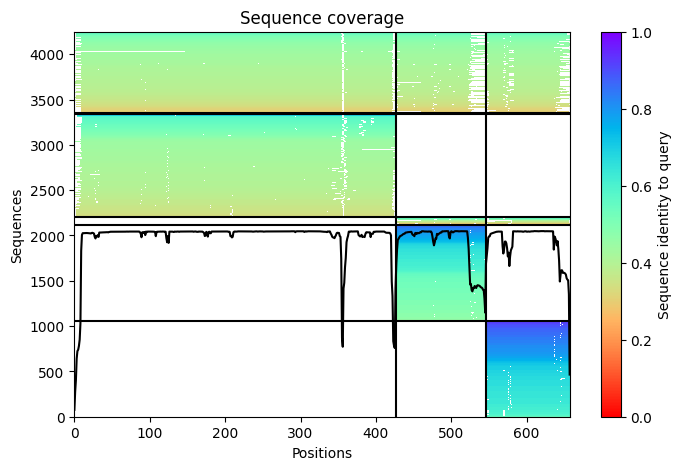

2026-10-11 22:07:21,777 Setting max_seq=508, max_extra_seq=2048


/content/alphafold/model/modules_multimer.py:114: UserWarning: Explicitly requested dtype int64 requested in broadcasted_iota is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  iota = jax.lax.broadcasted_iota(jnp.int64, logits.shape, axis)


2026-10-11 22:08:17,261 alphafold2_multimer_v3_model_1_seed_000 recycle=0 pLDDT=85.4 pTM=0.594 ipTM=0.326
2026-10-11 22:08:25,556 alphafold2_multimer_v3_model_1_seed_000 recycle=1 pLDDT=86.7 pTM=0.63 ipTM=0.368 tol=6.82
2026-10-11 22:08:33,834 alphafold2_multimer_v3_model_1_seed_000 recycle=2 pLDDT=86.6 pTM=0.621 ipTM=0.333 tol=1.1
2026-10-11 22:08:42,119 alphafold2_multimer_v3_model_1_seed_000 recycle=3 pLDDT=87.2 pTM=0.618 ipTM=0.326 tol=0.473
2026-10-11 22:08:42,120 alphafold2_multimer_v3_model_1_seed_000 took 71.8s (3 recycles)


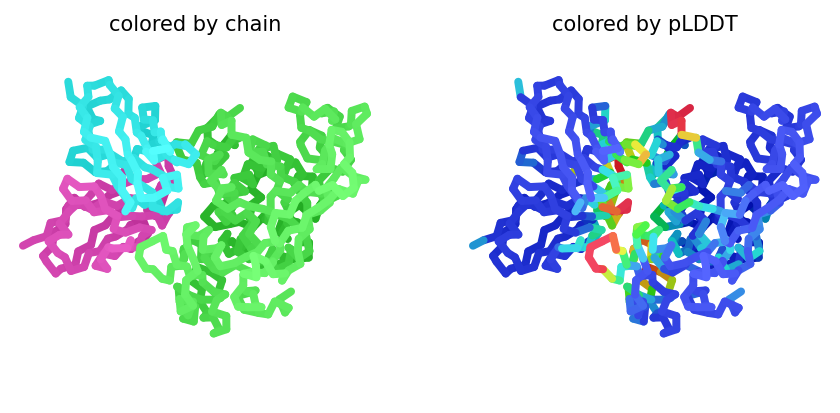

2026-10-11 22:08:50,775 alphafold2_multimer_v3_model_2_seed_000 recycle=0 pLDDT=85.1 pTM=0.609 ipTM=0.332
2026-10-11 22:08:59,064 alphafold2_multimer_v3_model_2_seed_000 recycle=1 pLDDT=86.4 pTM=0.615 ipTM=0.349 tol=2.66
2026-10-11 22:09:07,333 alphafold2_multimer_v3_model_2_seed_000 recycle=2 pLDDT=86.2 pTM=0.598 ipTM=0.338 tol=2.44
2026-10-11 22:09:15,605 alphafold2_multimer_v3_model_2_seed_000 recycle=3 pLDDT=86.6 pTM=0.609 ipTM=0.344 tol=2.41
2026-10-11 22:09:23,869 alphafold2_multimer_v3_model_2_seed_000 recycle=4 pLDDT=87 pTM=0.611 ipTM=0.347 tol=2.28
2026-10-11 22:09:32,143 alphafold2_multimer_v3_model_2_seed_000 recycle=5 pLDDT=87.2 pTM=0.606 ipTM=0.337 tol=0.541
2026-10-11 22:09:40,413 alphafold2_multimer_v3_model_2_seed_000 recycle=6 pLDDT=87.1 pTM=0.613 ipTM=0.349 tol=1.23
2026-10-11 22:09:48,689 alphafold2_multimer_v3_model_2_seed_000 recycle=7 pLDDT=87.3 pTM=0.612 ipTM=0.337 tol=1.36
2026-10-11 22:09:56,957 alphafold2_multimer_v3_model_2_seed_000 recycle=8 pLDDT=87.2 pTM=0

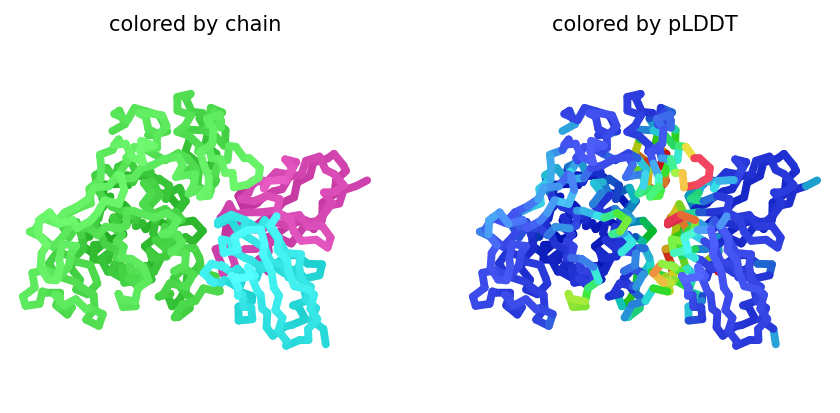

2026-10-11 22:11:03,506 alphafold2_multimer_v3_model_3_seed_000 recycle=0 pLDDT=86.1 pTM=0.625 ipTM=0.341
2026-10-11 22:11:11,808 alphafold2_multimer_v3_model_3_seed_000 recycle=1 pLDDT=87.9 pTM=0.649 ipTM=0.344 tol=2.28
2026-10-11 22:11:20,093 alphafold2_multimer_v3_model_3_seed_000 recycle=2 pLDDT=87.8 pTM=0.64 ipTM=0.326 tol=2.71
2026-10-11 22:11:28,379 alphafold2_multimer_v3_model_3_seed_000 recycle=3 pLDDT=87.9 pTM=0.707 ipTM=0.431 tol=6.48
2026-10-11 22:11:36,661 alphafold2_multimer_v3_model_3_seed_000 recycle=4 pLDDT=88.1 pTM=0.644 ipTM=0.323 tol=3.09
2026-10-11 22:11:44,947 alphafold2_multimer_v3_model_3_seed_000 recycle=5 pLDDT=88.1 pTM=0.651 ipTM=0.336 tol=1.22
2026-10-11 22:11:53,225 alphafold2_multimer_v3_model_3_seed_000 recycle=6 pLDDT=88.2 pTM=0.65 ipTM=0.33 tol=1.15
2026-10-11 22:12:01,500 alphafold2_multimer_v3_model_3_seed_000 recycle=7 pLDDT=88.1 pTM=0.648 ipTM=0.326 tol=1.01
2026-10-11 22:12:09,785 alphafold2_multimer_v3_model_3_seed_000 recycle=8 pLDDT=88.4 pTM=0.6

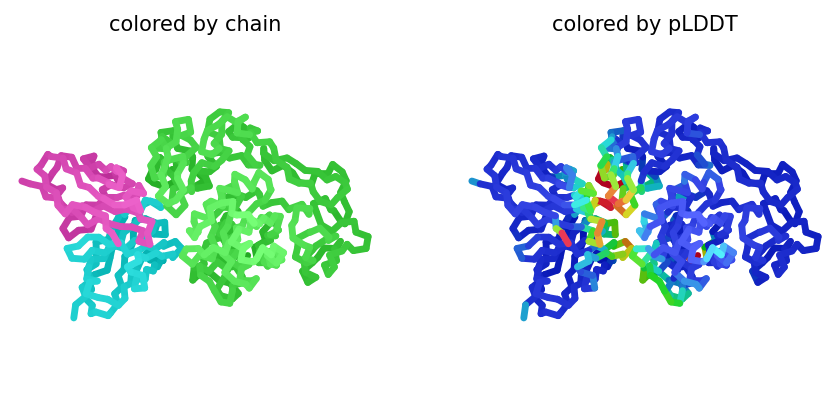

2026-10-11 22:13:57,946 alphafold2_multimer_v3_model_4_seed_000 recycle=0 pLDDT=84.1 pTM=0.617 ipTM=0.353
2026-10-11 22:14:06,234 alphafold2_multimer_v3_model_4_seed_000 recycle=1 pLDDT=85.9 pTM=0.618 ipTM=0.335 tol=5.64
2026-10-11 22:14:14,510 alphafold2_multimer_v3_model_4_seed_000 recycle=2 pLDDT=85.8 pTM=0.616 ipTM=0.335 tol=2.38
2026-10-11 22:14:22,784 alphafold2_multimer_v3_model_4_seed_000 recycle=3 pLDDT=85.7 pTM=0.623 ipTM=0.342 tol=2.23
2026-10-11 22:14:31,078 alphafold2_multimer_v3_model_4_seed_000 recycle=4 pLDDT=85.9 pTM=0.617 ipTM=0.338 tol=2.08
2026-10-11 22:14:39,370 alphafold2_multimer_v3_model_4_seed_000 recycle=5 pLDDT=83.2 pTM=0.786 ipTM=0.642 tol=7.41
2026-10-11 22:14:47,642 alphafold2_multimer_v3_model_4_seed_000 recycle=6 pLDDT=86.4 pTM=0.627 ipTM=0.34 tol=6.76
2026-10-11 22:14:55,912 alphafold2_multimer_v3_model_4_seed_000 recycle=7 pLDDT=86.1 pTM=0.622 ipTM=0.342 tol=1.24
2026-10-11 22:15:04,195 alphafold2_multimer_v3_model_4_seed_000 recycle=8 pLDDT=82.8 pTM=0

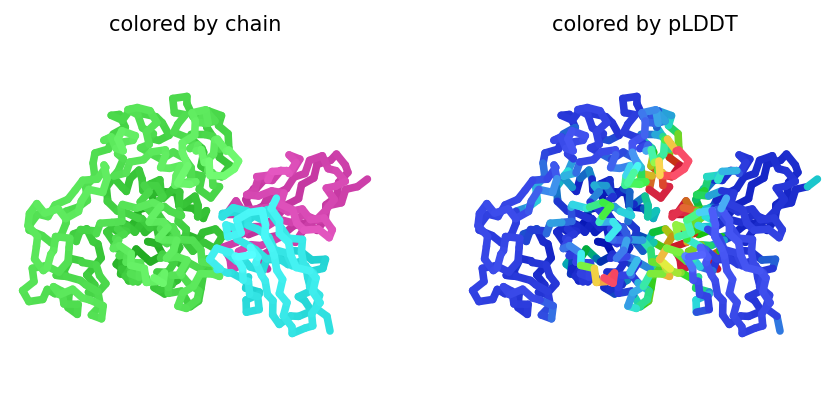

2026-10-11 22:16:52,111 alphafold2_multimer_v3_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.604 ipTM=0.33
2026-10-11 22:17:00,408 alphafold2_multimer_v3_model_5_seed_000 recycle=1 pLDDT=86.2 pTM=0.61 ipTM=0.328 tol=5.38
2026-10-11 22:17:08,671 alphafold2_multimer_v3_model_5_seed_000 recycle=2 pLDDT=86.3 pTM=0.7 ipTM=0.477 tol=6.13
2026-10-11 22:17:16,947 alphafold2_multimer_v3_model_5_seed_000 recycle=3 pLDDT=86.7 pTM=0.624 ipTM=0.347 tol=3.98
2026-10-11 22:17:25,227 alphafold2_multimer_v3_model_5_seed_000 recycle=4 pLDDT=86.4 pTM=0.63 ipTM=0.364 tol=1.16
2026-10-11 22:17:33,508 alphafold2_multimer_v3_model_5_seed_000 recycle=5 pLDDT=86.6 pTM=0.655 ipTM=0.392 tol=0.68
2026-10-11 22:17:41,790 alphafold2_multimer_v3_model_5_seed_000 recycle=6 pLDDT=86.9 pTM=0.633 ipTM=0.361 tol=0.733
2026-10-11 22:17:50,063 alphafold2_multimer_v3_model_5_seed_000 recycle=7 pLDDT=86.7 pTM=0.692 ipTM=0.463 tol=1.71
2026-10-11 22:17:58,342 alphafold2_multimer_v3_model_5_seed_000 recycle=8 pLDDT=87.4 pTM=0.63

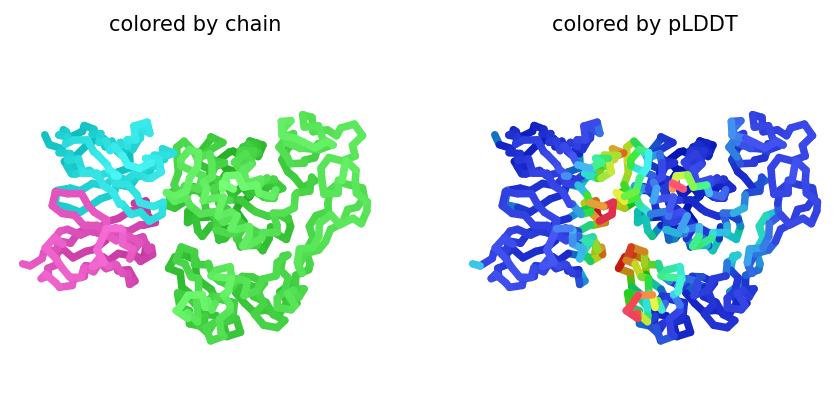

2026-10-11 22:18:15,277 alphafold2_multimer_v3_model_1_seed_001 recycle=0 pLDDT=86 pTM=0.594 ipTM=0.319
2026-10-11 22:18:23,584 alphafold2_multimer_v3_model_1_seed_001 recycle=1 pLDDT=87.4 pTM=0.64 ipTM=0.365 tol=5.31
2026-10-11 22:18:31,875 alphafold2_multimer_v3_model_1_seed_001 recycle=2 pLDDT=87.4 pTM=0.617 ipTM=0.32 tol=2.79
2026-10-11 22:18:40,165 alphafold2_multimer_v3_model_1_seed_001 recycle=3 pLDDT=86.4 pTM=0.755 ipTM=0.595 tol=7.57
2026-10-11 22:18:48,460 alphafold2_multimer_v3_model_1_seed_001 recycle=4 pLDDT=88.3 pTM=0.62 ipTM=0.323 tol=4.3
2026-10-11 22:18:56,748 alphafold2_multimer_v3_model_1_seed_001 recycle=5 pLDDT=87.9 pTM=0.611 ipTM=0.315 tol=2.43
2026-10-11 22:19:05,033 alphafold2_multimer_v3_model_1_seed_001 recycle=6 pLDDT=87.7 pTM=0.614 ipTM=0.321 tol=0.898
2026-10-11 22:19:13,319 alphafold2_multimer_v3_model_1_seed_001 recycle=7 pLDDT=87.6 pTM=0.613 ipTM=0.314 tol=0.899
2026-10-11 22:19:21,602 alphafold2_multimer_v3_model_1_seed_001 recycle=8 pLDDT=87.1 pTM=0.73

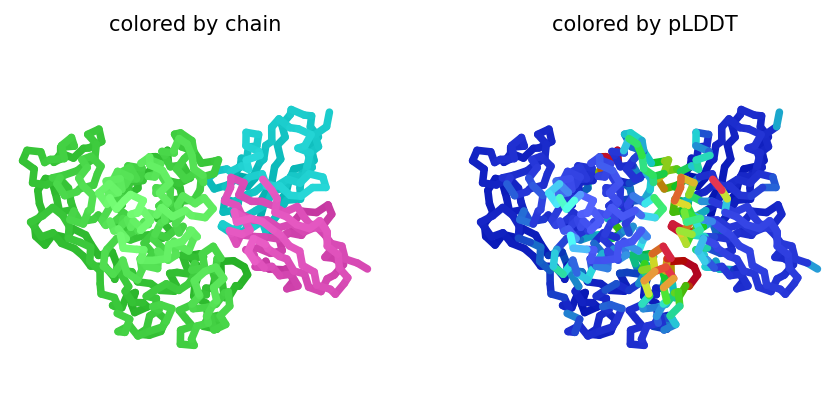

2026-10-11 22:20:03,404 alphafold2_multimer_v3_model_2_seed_001 recycle=0 pLDDT=85.2 pTM=0.61 ipTM=0.337
2026-10-11 22:20:11,689 alphafold2_multimer_v3_model_2_seed_001 recycle=1 pLDDT=86.8 pTM=0.623 ipTM=0.352 tol=1.61
2026-10-11 22:20:19,968 alphafold2_multimer_v3_model_2_seed_001 recycle=2 pLDDT=86.7 pTM=0.611 ipTM=0.337 tol=2.99
2026-10-11 22:20:28,240 alphafold2_multimer_v3_model_2_seed_001 recycle=3 pLDDT=86.7 pTM=0.609 ipTM=0.34 tol=1.27
2026-10-11 22:20:36,513 alphafold2_multimer_v3_model_2_seed_001 recycle=4 pLDDT=87.3 pTM=0.614 ipTM=0.342 tol=1.04
2026-10-11 22:20:44,787 alphafold2_multimer_v3_model_2_seed_001 recycle=5 pLDDT=87.1 pTM=0.615 ipTM=0.339 tol=2.24
2026-10-11 22:20:53,066 alphafold2_multimer_v3_model_2_seed_001 recycle=6 pLDDT=87.5 pTM=0.617 ipTM=0.338 tol=0.906
2026-10-11 22:21:01,344 alphafold2_multimer_v3_model_2_seed_001 recycle=7 pLDDT=87.4 pTM=0.621 ipTM=0.347 tol=0.56
2026-10-11 22:21:09,621 alphafold2_multimer_v3_model_2_seed_001 recycle=8 pLDDT=87.4 pTM=0

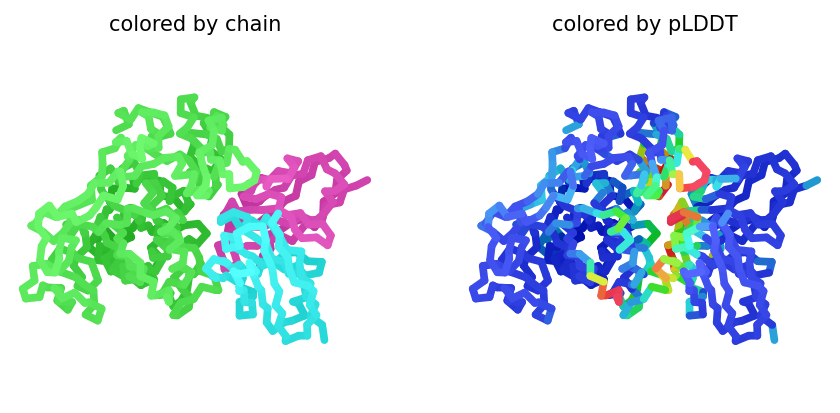

2026-10-11 22:21:34,840 alphafold2_multimer_v3_model_3_seed_001 recycle=0 pLDDT=87 pTM=0.629 ipTM=0.337
2026-10-11 22:21:43,154 alphafold2_multimer_v3_model_3_seed_001 recycle=1 pLDDT=88.3 pTM=0.649 ipTM=0.341 tol=3.99
2026-10-11 22:21:51,458 alphafold2_multimer_v3_model_3_seed_001 recycle=2 pLDDT=88.2 pTM=0.645 ipTM=0.333 tol=2.95
2026-10-11 22:21:59,750 alphafold2_multimer_v3_model_3_seed_001 recycle=3 pLDDT=88.1 pTM=0.645 ipTM=0.329 tol=2.79
2026-10-11 22:22:08,050 alphafold2_multimer_v3_model_3_seed_001 recycle=4 pLDDT=87.5 pTM=0.763 ipTM=0.546 tol=6.91
2026-10-11 22:22:16,353 alphafold2_multimer_v3_model_3_seed_001 recycle=5 pLDDT=88.6 pTM=0.657 ipTM=0.337 tol=2.24
2026-10-11 22:22:24,645 alphafold2_multimer_v3_model_3_seed_001 recycle=6 pLDDT=88.6 pTM=0.651 ipTM=0.326 tol=2.07
2026-10-11 22:22:32,950 alphafold2_multimer_v3_model_3_seed_001 recycle=7 pLDDT=88.8 pTM=0.649 ipTM=0.324 tol=3.2
2026-10-11 22:22:41,249 alphafold2_multimer_v3_model_3_seed_001 recycle=8 pLDDT=88.7 pTM=0.6

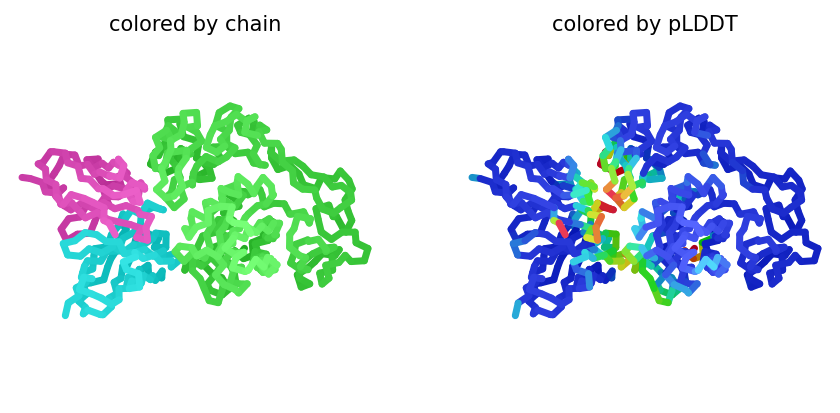

2026-10-11 22:24:29,384 alphafold2_multimer_v3_model_4_seed_001 recycle=0 pLDDT=84.1 pTM=0.607 ipTM=0.352
2026-10-11 22:24:37,670 alphafold2_multimer_v3_model_4_seed_001 recycle=1 pLDDT=85.9 pTM=0.58 ipTM=0.341 tol=2.36
2026-10-11 22:24:45,951 alphafold2_multimer_v3_model_4_seed_001 recycle=2 pLDDT=86.1 pTM=0.611 ipTM=0.373 tol=7.39
2026-10-11 22:24:54,226 alphafold2_multimer_v3_model_4_seed_001 recycle=3 pLDDT=85.9 pTM=0.591 ipTM=0.334 tol=5.79
2026-10-11 22:25:02,510 alphafold2_multimer_v3_model_4_seed_001 recycle=4 pLDDT=86.6 pTM=0.619 ipTM=0.34 tol=1.85
2026-10-11 22:25:10,791 alphafold2_multimer_v3_model_4_seed_001 recycle=5 pLDDT=86.8 pTM=0.611 ipTM=0.332 tol=1.03
2026-10-11 22:25:19,069 alphafold2_multimer_v3_model_4_seed_001 recycle=6 pLDDT=86.7 pTM=0.621 ipTM=0.339 tol=0.563
2026-10-11 22:25:27,348 alphafold2_multimer_v3_model_4_seed_001 recycle=7 pLDDT=86.9 pTM=0.617 ipTM=0.333 tol=0.458
2026-10-11 22:25:27,349 alphafold2_multimer_v3_model_4_seed_001 took 66.3s (7 recycles)


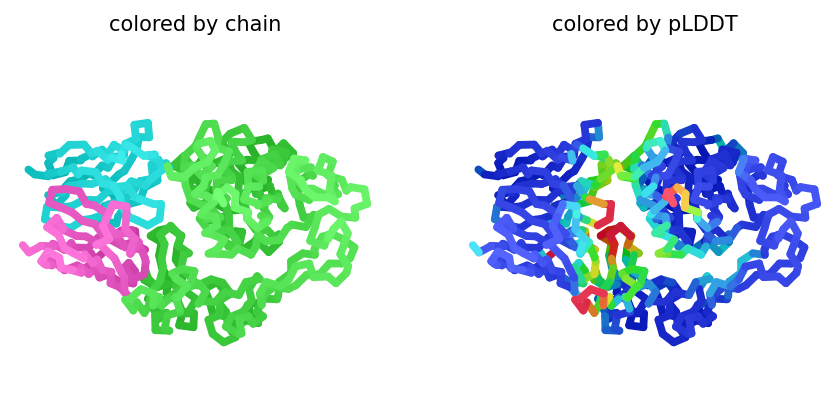

2026-10-11 22:25:36,011 alphafold2_multimer_v3_model_5_seed_001 recycle=0 pLDDT=85.8 pTM=0.599 ipTM=0.326
2026-10-11 22:25:44,325 alphafold2_multimer_v3_model_5_seed_001 recycle=1 pLDDT=86.9 pTM=0.624 ipTM=0.333 tol=7.53
2026-10-11 22:25:52,621 alphafold2_multimer_v3_model_5_seed_001 recycle=2 pLDDT=86.7 pTM=0.621 ipTM=0.331 tol=0.512
2026-10-11 22:26:00,914 alphafold2_multimer_v3_model_5_seed_001 recycle=3 pLDDT=86.1 pTM=0.792 ipTM=0.651 tol=5.26
2026-10-11 22:26:09,210 alphafold2_multimer_v3_model_5_seed_001 recycle=4 pLDDT=88 pTM=0.643 ipTM=0.352 tol=1.84
2026-10-11 22:26:17,501 alphafold2_multimer_v3_model_5_seed_001 recycle=5 pLDDT=87.6 pTM=0.649 ipTM=0.372 tol=0.822
2026-10-11 22:26:25,796 alphafold2_multimer_v3_model_5_seed_001 recycle=6 pLDDT=87.9 pTM=0.637 ipTM=0.349 tol=0.956
2026-10-11 22:26:34,095 alphafold2_multimer_v3_model_5_seed_001 recycle=7 pLDDT=87.8 pTM=0.638 ipTM=0.355 tol=0.741
2026-10-11 22:26:42,391 alphafold2_multimer_v3_model_5_seed_001 recycle=8 pLDDT=87.7 pT

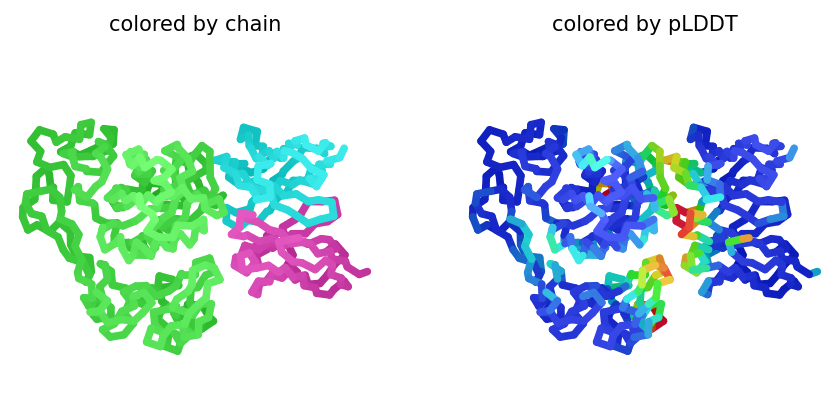

2026-10-11 22:26:59,308 alphafold2_multimer_v3_model_1_seed_002 recycle=0 pLDDT=85.5 pTM=0.586 ipTM=0.321
2026-10-11 22:27:07,602 alphafold2_multimer_v3_model_1_seed_002 recycle=1 pLDDT=87.2 pTM=0.648 ipTM=0.376 tol=4.36
2026-10-11 22:27:15,891 alphafold2_multimer_v3_model_1_seed_002 recycle=2 pLDDT=87.1 pTM=0.617 ipTM=0.321 tol=2.32
2026-10-11 22:27:24,165 alphafold2_multimer_v3_model_1_seed_002 recycle=3 pLDDT=86.8 pTM=0.662 ipTM=0.431 tol=5.38
2026-10-11 22:27:32,457 alphafold2_multimer_v3_model_1_seed_002 recycle=4 pLDDT=87.9 pTM=0.618 ipTM=0.321 tol=2.58
2026-10-11 22:27:40,745 alphafold2_multimer_v3_model_1_seed_002 recycle=5 pLDDT=87.6 pTM=0.608 ipTM=0.317 tol=2.14
2026-10-11 22:27:49,023 alphafold2_multimer_v3_model_1_seed_002 recycle=6 pLDDT=87.6 pTM=0.61 ipTM=0.323 tol=0.641
2026-10-11 22:27:57,315 alphafold2_multimer_v3_model_1_seed_002 recycle=7 pLDDT=87.6 pTM=0.608 ipTM=0.32 tol=0.605
2026-10-11 22:28:05,598 alphafold2_multimer_v3_model_1_seed_002 recycle=8 pLDDT=87.4 pTM=

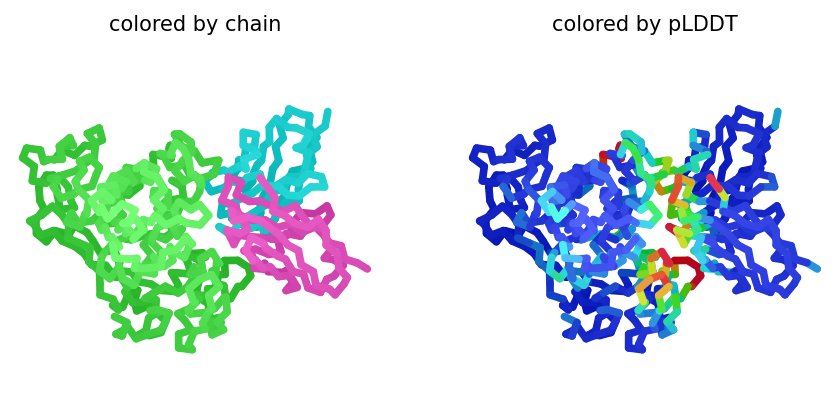

2026-10-11 22:28:14,234 alphafold2_multimer_v3_model_2_seed_002 recycle=0 pLDDT=84.6 pTM=0.588 ipTM=0.358
2026-10-11 22:28:22,523 alphafold2_multimer_v3_model_2_seed_002 recycle=1 pLDDT=86.2 pTM=0.618 ipTM=0.37 tol=3.55
2026-10-11 22:28:30,803 alphafold2_multimer_v3_model_2_seed_002 recycle=2 pLDDT=86.7 pTM=0.6 ipTM=0.342 tol=3.22
2026-10-11 22:28:39,077 alphafold2_multimer_v3_model_2_seed_002 recycle=3 pLDDT=86.4 pTM=0.662 ipTM=0.453 tol=4.77
2026-10-11 22:28:47,361 alphafold2_multimer_v3_model_2_seed_002 recycle=4 pLDDT=87.5 pTM=0.611 ipTM=0.35 tol=4.19
2026-10-11 22:28:55,647 alphafold2_multimer_v3_model_2_seed_002 recycle=5 pLDDT=87.2 pTM=0.602 ipTM=0.341 tol=0.739
2026-10-11 22:29:03,918 alphafold2_multimer_v3_model_2_seed_002 recycle=6 pLDDT=87.1 pTM=0.604 ipTM=0.349 tol=1.07
2026-10-11 22:29:12,193 alphafold2_multimer_v3_model_2_seed_002 recycle=7 pLDDT=87.2 pTM=0.601 ipTM=0.34 tol=0.91
2026-10-11 22:29:20,471 alphafold2_multimer_v3_model_2_seed_002 recycle=8 pLDDT=87.1 pTM=0.60

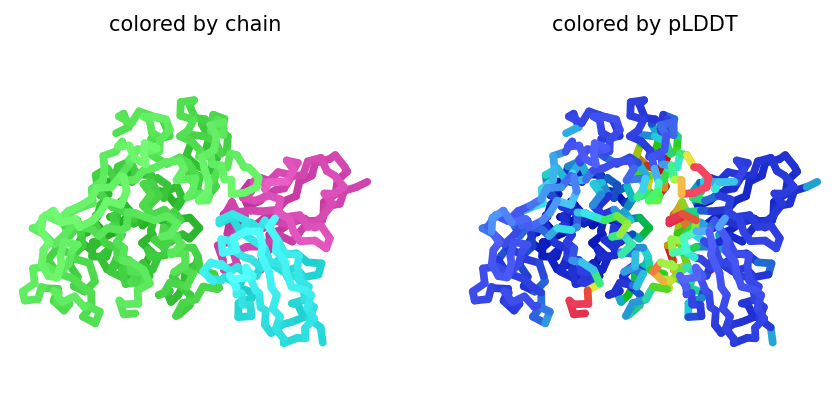

2026-10-11 22:30:35,322 alphafold2_multimer_v3_model_3_seed_002 recycle=0 pLDDT=85.7 pTM=0.607 ipTM=0.332
2026-10-11 22:30:43,633 alphafold2_multimer_v3_model_3_seed_002 recycle=1 pLDDT=88.2 pTM=0.644 ipTM=0.341 tol=1.78
2026-10-11 22:30:51,929 alphafold2_multimer_v3_model_3_seed_002 recycle=2 pLDDT=88.2 pTM=0.642 ipTM=0.333 tol=1.65
2026-10-11 22:31:00,214 alphafold2_multimer_v3_model_3_seed_002 recycle=3 pLDDT=88.4 pTM=0.708 ipTM=0.441 tol=5.79
2026-10-11 22:31:08,503 alphafold2_multimer_v3_model_3_seed_002 recycle=4 pLDDT=88.2 pTM=0.645 ipTM=0.321 tol=4.3
2026-10-11 22:31:16,791 alphafold2_multimer_v3_model_3_seed_002 recycle=5 pLDDT=88.1 pTM=0.648 ipTM=0.336 tol=1.43
2026-10-11 22:31:25,073 alphafold2_multimer_v3_model_3_seed_002 recycle=6 pLDDT=88.2 pTM=0.646 ipTM=0.322 tol=0.593
2026-10-11 22:31:33,358 alphafold2_multimer_v3_model_3_seed_002 recycle=7 pLDDT=88.4 pTM=0.653 ipTM=0.338 tol=1.45
2026-10-11 22:31:41,657 alphafold2_multimer_v3_model_3_seed_002 recycle=8 pLDDT=88.5 pTM=

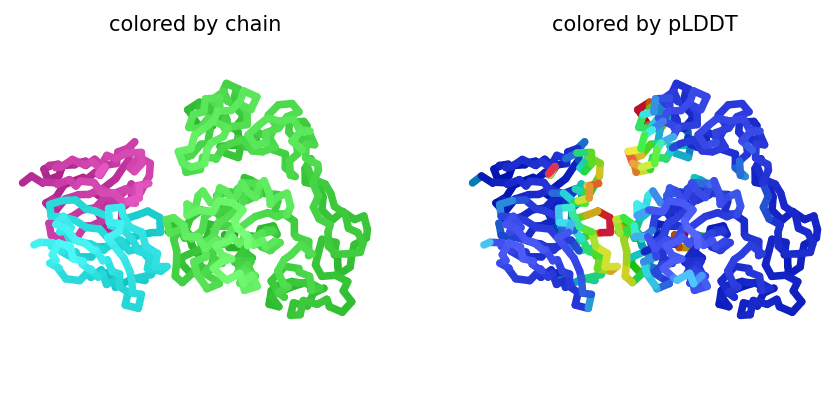

2026-10-11 22:33:29,830 alphafold2_multimer_v3_model_4_seed_002 recycle=0 pLDDT=84.4 pTM=0.593 ipTM=0.35
2026-10-11 22:33:38,116 alphafold2_multimer_v3_model_4_seed_002 recycle=1 pLDDT=85.9 pTM=0.604 ipTM=0.339 tol=2.03
2026-10-11 22:33:46,391 alphafold2_multimer_v3_model_4_seed_002 recycle=2 pLDDT=85.7 pTM=0.624 ipTM=0.346 tol=4.64
2026-10-11 22:33:54,666 alphafold2_multimer_v3_model_4_seed_002 recycle=3 pLDDT=85.1 pTM=0.7 ipTM=0.486 tol=6.11
2026-10-11 22:34:02,949 alphafold2_multimer_v3_model_4_seed_002 recycle=4 pLDDT=86.1 pTM=0.672 ipTM=0.414 tol=1.47
2026-10-11 22:34:11,216 alphafold2_multimer_v3_model_4_seed_002 recycle=5 pLDDT=85.6 pTM=0.644 ipTM=0.369 tol=1.3
2026-10-11 22:34:19,487 alphafold2_multimer_v3_model_4_seed_002 recycle=6 pLDDT=86.2 pTM=0.625 ipTM=0.335 tol=2.37
2026-10-11 22:34:27,766 alphafold2_multimer_v3_model_4_seed_002 recycle=7 pLDDT=84.6 pTM=0.759 ipTM=0.586 tol=4.97
2026-10-11 22:34:36,042 alphafold2_multimer_v3_model_4_seed_002 recycle=8 pLDDT=86.6 pTM=0.63

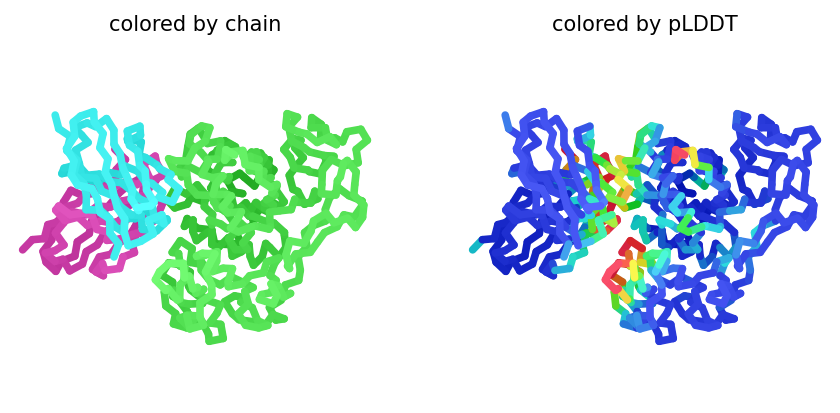

2026-10-11 22:36:23,943 alphafold2_multimer_v3_model_5_seed_002 recycle=0 pLDDT=84.8 pTM=0.584 ipTM=0.319
2026-10-11 22:36:32,249 alphafold2_multimer_v3_model_5_seed_002 recycle=1 pLDDT=86.8 pTM=0.623 ipTM=0.333 tol=3.9
2026-10-11 22:36:40,527 alphafold2_multimer_v3_model_5_seed_002 recycle=2 pLDDT=86.8 pTM=0.741 ipTM=0.552 tol=5.38
2026-10-11 22:36:48,809 alphafold2_multimer_v3_model_5_seed_002 recycle=3 pLDDT=87.1 pTM=0.625 ipTM=0.345 tol=3.54
2026-10-11 22:36:57,091 alphafold2_multimer_v3_model_5_seed_002 recycle=4 pLDDT=86.9 pTM=0.642 ipTM=0.37 tol=1.66
2026-10-11 22:37:05,369 alphafold2_multimer_v3_model_5_seed_002 recycle=5 pLDDT=87 pTM=0.622 ipTM=0.348 tol=2.38
2026-10-11 22:37:13,642 alphafold2_multimer_v3_model_5_seed_002 recycle=6 pLDDT=86.9 pTM=0.624 ipTM=0.349 tol=1.17
2026-10-11 22:37:21,921 alphafold2_multimer_v3_model_5_seed_002 recycle=7 pLDDT=86.9 pTM=0.637 ipTM=0.368 tol=1.73
2026-10-11 22:37:30,208 alphafold2_multimer_v3_model_5_seed_002 recycle=8 pLDDT=87.4 pTM=0.63

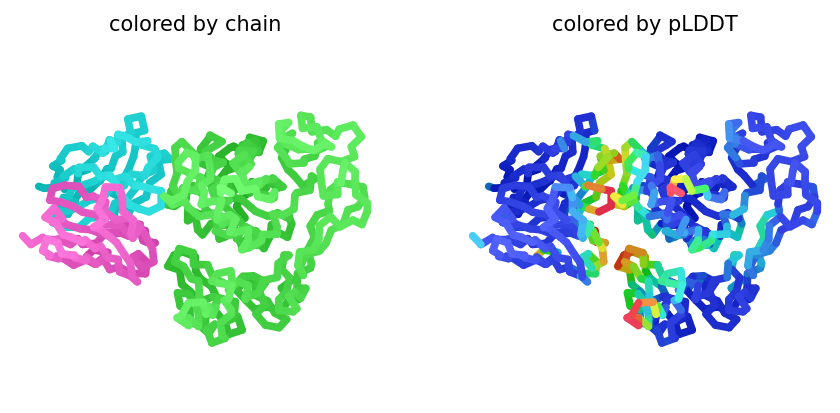

2026-10-11 22:39:18,261 alphafold2_multimer_v3_model_1_seed_003 recycle=0 pLDDT=84.6 pTM=0.615 ipTM=0.342
2026-10-11 22:39:26,558 alphafold2_multimer_v3_model_1_seed_003 recycle=1 pLDDT=86.8 pTM=0.636 ipTM=0.356 tol=3.21
2026-10-11 22:39:34,848 alphafold2_multimer_v3_model_1_seed_003 recycle=2 pLDDT=87.2 pTM=0.615 ipTM=0.31 tol=4.08
2026-10-11 22:39:43,139 alphafold2_multimer_v3_model_1_seed_003 recycle=3 pLDDT=87.6 pTM=0.611 ipTM=0.306 tol=1.37
2026-10-11 22:39:51,424 alphafold2_multimer_v3_model_1_seed_003 recycle=4 pLDDT=87.6 pTM=0.609 ipTM=0.312 tol=0.958
2026-10-11 22:39:59,708 alphafold2_multimer_v3_model_1_seed_003 recycle=5 pLDDT=87.3 pTM=0.608 ipTM=0.318 tol=1.56
2026-10-11 22:40:07,988 alphafold2_multimer_v3_model_1_seed_003 recycle=6 pLDDT=87.6 pTM=0.612 ipTM=0.32 tol=1.05
2026-10-11 22:40:16,271 alphafold2_multimer_v3_model_1_seed_003 recycle=7 pLDDT=87.4 pTM=0.609 ipTM=0.321 tol=0.607
2026-10-11 22:40:24,556 alphafold2_multimer_v3_model_1_seed_003 recycle=8 pLDDT=87.6 pTM=

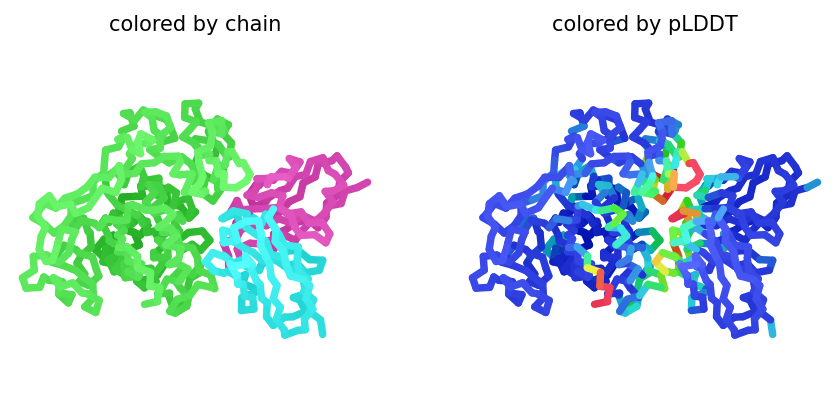

2026-10-11 22:40:33,195 alphafold2_multimer_v3_model_2_seed_003 recycle=0 pLDDT=85.2 pTM=0.619 ipTM=0.343
2026-10-11 22:40:41,497 alphafold2_multimer_v3_model_2_seed_003 recycle=1 pLDDT=87.2 pTM=0.626 ipTM=0.337 tol=2.67
2026-10-11 22:40:49,777 alphafold2_multimer_v3_model_2_seed_003 recycle=2 pLDDT=87 pTM=0.616 ipTM=0.335 tol=0.627
2026-10-11 22:40:58,049 alphafold2_multimer_v3_model_2_seed_003 recycle=3 pLDDT=87.4 pTM=0.643 ipTM=0.379 tol=3.04
2026-10-11 22:41:06,326 alphafold2_multimer_v3_model_2_seed_003 recycle=4 pLDDT=87.8 pTM=0.625 ipTM=0.353 tol=3.62
2026-10-11 22:41:14,603 alphafold2_multimer_v3_model_2_seed_003 recycle=5 pLDDT=87.6 pTM=0.613 ipTM=0.336 tol=0.477
2026-10-11 22:41:14,604 alphafold2_multimer_v3_model_2_seed_003 took 49.7s (5 recycles)


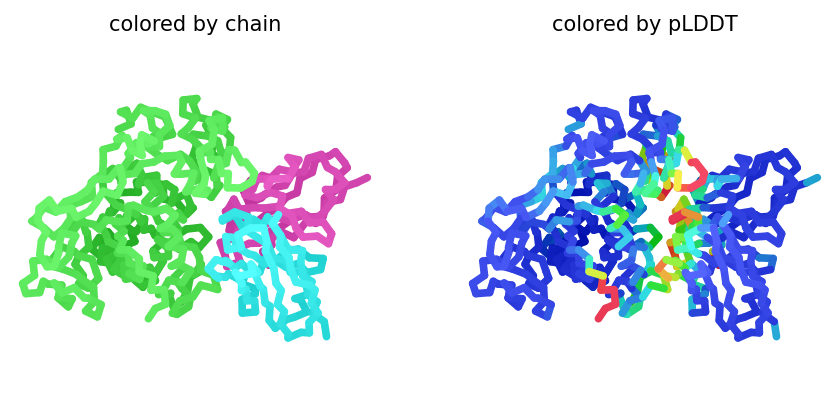

2026-10-11 22:41:23,255 alphafold2_multimer_v3_model_3_seed_003 recycle=0 pLDDT=86.5 pTM=0.639 ipTM=0.34
2026-10-11 22:41:31,559 alphafold2_multimer_v3_model_3_seed_003 recycle=1 pLDDT=87.9 pTM=0.651 ipTM=0.336 tol=1.43
2026-10-11 22:41:39,856 alphafold2_multimer_v3_model_3_seed_003 recycle=2 pLDDT=88.2 pTM=0.645 ipTM=0.333 tol=1.35
2026-10-11 22:41:48,145 alphafold2_multimer_v3_model_3_seed_003 recycle=3 pLDDT=88.2 pTM=0.697 ipTM=0.413 tol=4.67
2026-10-11 22:41:56,426 alphafold2_multimer_v3_model_3_seed_003 recycle=4 pLDDT=88.3 pTM=0.648 ipTM=0.326 tol=2.67
2026-10-11 22:42:04,749 alphafold2_multimer_v3_model_3_seed_003 recycle=5 pLDDT=88.3 pTM=0.65 ipTM=0.327 tol=1.13
2026-10-11 22:42:13,045 alphafold2_multimer_v3_model_3_seed_003 recycle=6 pLDDT=88.8 pTM=0.698 ipTM=0.406 tol=2.88
2026-10-11 22:42:21,333 alphafold2_multimer_v3_model_3_seed_003 recycle=7 pLDDT=88.6 pTM=0.645 ipTM=0.322 tol=3.87
2026-10-11 22:42:29,621 alphafold2_multimer_v3_model_3_seed_003 recycle=8 pLDDT=88.7 pTM=0.

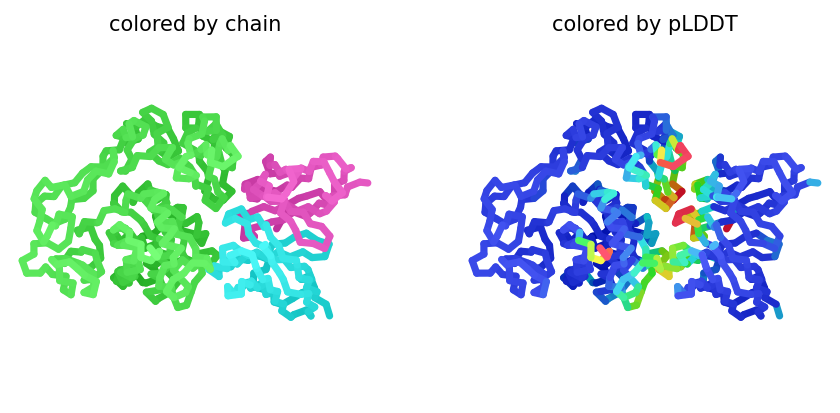

2026-10-11 22:44:17,793 alphafold2_multimer_v3_model_4_seed_003 recycle=0 pLDDT=84.7 pTM=0.599 ipTM=0.338
2026-10-11 22:44:26,069 alphafold2_multimer_v3_model_4_seed_003 recycle=1 pLDDT=85.7 pTM=0.617 ipTM=0.343 tol=2.06
2026-10-11 22:44:34,358 alphafold2_multimer_v3_model_4_seed_003 recycle=2 pLDDT=86.4 pTM=0.626 ipTM=0.337 tol=0.91
2026-10-11 22:44:42,640 alphafold2_multimer_v3_model_4_seed_003 recycle=3 pLDDT=86.4 pTM=0.629 ipTM=0.345 tol=1.3
2026-10-11 22:44:50,927 alphafold2_multimer_v3_model_4_seed_003 recycle=4 pLDDT=85.7 pTM=0.757 ipTM=0.571 tol=5.52
2026-10-11 22:44:59,206 alphafold2_multimer_v3_model_4_seed_003 recycle=5 pLDDT=86.8 pTM=0.64 ipTM=0.349 tol=5.17
2026-10-11 22:45:07,487 alphafold2_multimer_v3_model_4_seed_003 recycle=6 pLDDT=86.8 pTM=0.639 ipTM=0.343 tol=1.24
2026-10-11 22:45:15,770 alphafold2_multimer_v3_model_4_seed_003 recycle=7 pLDDT=84.9 pTM=0.737 ipTM=0.543 tol=7.25
2026-10-11 22:45:24,055 alphafold2_multimer_v3_model_4_seed_003 recycle=8 pLDDT=86.8 pTM=0.

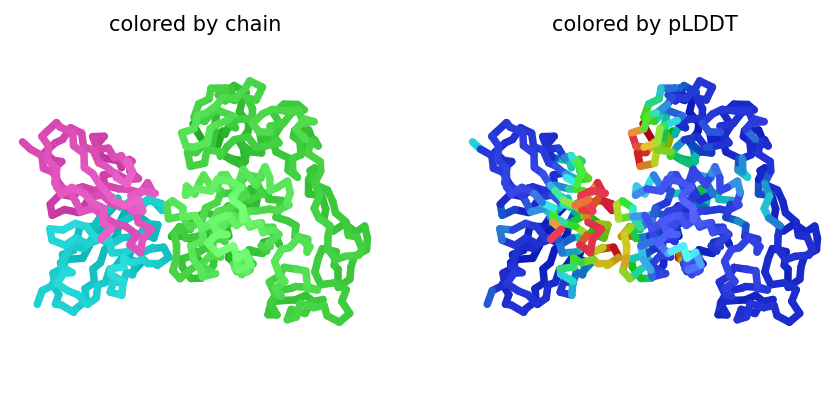

2026-10-11 22:47:12,025 alphafold2_multimer_v3_model_5_seed_003 recycle=0 pLDDT=85 pTM=0.605 ipTM=0.322
2026-10-11 22:47:20,328 alphafold2_multimer_v3_model_5_seed_003 recycle=1 pLDDT=86.4 pTM=0.627 ipTM=0.34 tol=4.04
2026-10-11 22:47:28,629 alphafold2_multimer_v3_model_5_seed_003 recycle=2 pLDDT=87 pTM=0.64 ipTM=0.356 tol=1.71
2026-10-11 22:47:36,928 alphafold2_multimer_v3_model_5_seed_003 recycle=3 pLDDT=87.1 pTM=0.631 ipTM=0.345 tol=1.17
2026-10-11 22:47:45,212 alphafold2_multimer_v3_model_5_seed_003 recycle=4 pLDDT=86.9 pTM=0.642 ipTM=0.365 tol=1.51
2026-10-11 22:47:53,501 alphafold2_multimer_v3_model_5_seed_003 recycle=5 pLDDT=86.8 pTM=0.655 ipTM=0.382 tol=0.752
2026-10-11 22:48:01,791 alphafold2_multimer_v3_model_5_seed_003 recycle=6 pLDDT=87.3 pTM=0.642 ipTM=0.357 tol=1.25
2026-10-11 22:48:10,077 alphafold2_multimer_v3_model_5_seed_003 recycle=7 pLDDT=86.2 pTM=0.758 ipTM=0.579 tol=2.54
2026-10-11 22:48:18,361 alphafold2_multimer_v3_model_5_seed_003 recycle=8 pLDDT=87.3 pTM=0.635

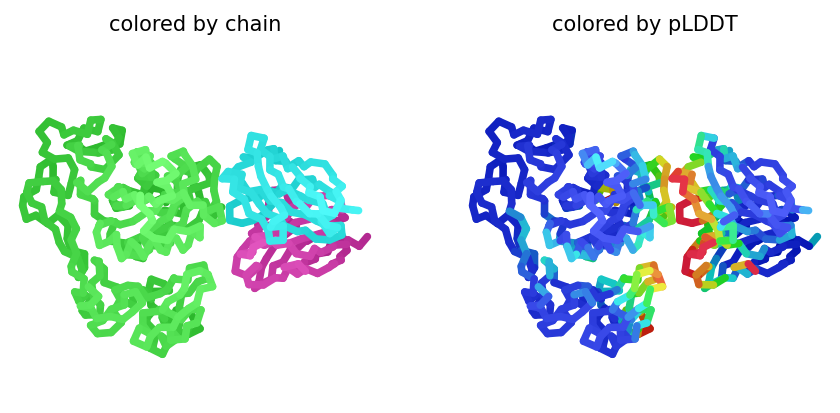

2026-10-11 22:49:58,185 reranking models by 'multimer' metric
2026-10-11 22:49:58,186 rank_001_alphafold2_multimer_v3_model_5_seed_003 pLDDT=85.6 pTM=0.772 ipTM=0.615 ipSAE=A-B:0.326,A-C:0.261,B-C:0.756 pDockQ2=A-B:0.0283,A-C:0.0207,B-C:0.296
2026-10-11 22:49:58,186 rank_002_alphafold2_multimer_v3_model_4_seed_003 pLDDT=85.8 pTM=0.717 ipTM=0.518 ipSAE=A-B:0.132,A-C:0.096,B-C:0.77 pDockQ2=A-B:0.0181,A-C:0.0145,B-C:0.335
2026-10-11 22:49:58,186 rank_003_alphafold2_multimer_v3_model_3_seed_002 pLDDT=88.5 pTM=0.728 ipTM=0.481 ipSAE=A-B:0.113,A-C:0.0795,B-C:0.619 pDockQ2=A-B:0.0195,A-C:0,B-C:0.467
2026-10-11 22:49:58,186 rank_004_alphafold2_multimer_v3_model_5_seed_000 pLDDT=87.1 pTM=0.637 ipTM=0.366 ipSAE=A-B:0.00553,A-C:0.00534,B-C:0.729 pDockQ2=A-B:0.0112,A-C:0.0095,B-C:0.492
2026-10-11 22:49:58,187 rank_005_alphafold2_multimer_v3_model_5_seed_002 pLDDT=87.3 pTM=0.641 ipTM=0.365 ipSAE=A-B:0.00546,A-C:0.00532,B-C:0.726 pDockQ2=A-B:0.0111,A-C:0.0098,B-C:0.523
2026-10-11 22:49:58,187 rank_0

0

In [6]:
#@title Run Prediction
display_images = True #@param {type:"boolean"}

import sys
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
from Bio import BiopythonDeprecationWarning
warnings.simplefilter(action='ignore', category=BiopythonDeprecationWarning)
from pathlib import Path
from colabfold.download import download_alphafold_params, default_data_dir
from colabfold.utils import setup_logging
from colabfold.batch import get_queries, run, set_model_type
from colabfold.plot import plot_msa_v2

import os
import numpy as np
try:
  K80_chk = os.popen('nvidia-smi | grep "Tesla K80" | wc -l').read()
except:
  K80_chk = "0"
  pass
if "1" in K80_chk:
  print("WARNING: found GPU Tesla K80: limited to total length < 1000")
  if "TF_FORCE_UNIFIED_MEMORY" in os.environ:
    del os.environ["TF_FORCE_UNIFIED_MEMORY"]
  if "XLA_PYTHON_CLIENT_MEM_FRACTION" in os.environ:
    del os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]

from colabfold.colabfold import plot_protein
from pathlib import Path
import matplotlib.pyplot as plt

def input_features_callback(input_features):
  if display_images:
    plot_msa_v2(input_features)
    plt.show()
    plt.close()

def prediction_callback(protein_obj, length,
                        prediction_result, input_features, mode):
  model_name, relaxed = mode
  if not relaxed:
    if display_images:
      fig = plot_protein(protein_obj, Ls=length, dpi=150)
      plt.show()
      plt.close()

result_dir = jobname
log_filename = os.path.join(jobname,"log.txt")
setup_logging(Path(log_filename))

queries, is_complex = get_queries(queries_path)
model_type = set_model_type(is_complex, model_type)

if "multimer" in model_type and max_msa is not None:
  use_cluster_profile = False
else:
  use_cluster_profile = True

download_alphafold_params(model_type, Path("."))
results = run(
    queries=queries,
    result_dir=result_dir,
    use_templates=use_templates,
    custom_template_path=custom_template_path,
    num_relax=num_relax,
    msa_mode=msa_mode,
    model_type=model_type,
    num_models=5,
    num_recycles=num_recycles,
    relax_max_iterations=relax_max_iterations,
    recycle_early_stop_tolerance=recycle_early_stop_tolerance,
    num_seeds=num_seeds,
    use_dropout=use_dropout,
    use_fast_kernels=use_fast_kernels,
    model_order=[1,2,3,4,5],
    is_complex=is_complex,
    data_dir=Path("."),
    keep_existing_results=False,
    rank_by="auto",
    pair_mode=pair_mode,
    pairing_strategy=pairing_strategy,
    stop_at_score=float(100),
    prediction_callback=prediction_callback,
    dpi=dpi,
    zip_results=False,
    save_all=save_all,
    max_msa=max_msa,
    use_cluster_profile=use_cluster_profile,
    input_features_callback=input_features_callback,
    save_recycles=save_recycles,
    user_agent="colabfold/google-colab-main",
    calc_extra_ptm=calc_extra_ptm,
)
results_zip = f"{jobname}.result.zip"
os.system(f"zip -r {results_zip} {jobname}")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

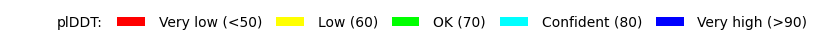

In [7]:
#@title Display 3D structure {run: "auto"}
import py3Dmol
import glob
import matplotlib.pyplot as plt
from colabfold.colabfold import plot_plddt_legend
from colabfold.colabfold import pymol_color_list, alphabet_list
rank_num = 1 #@param ["1", "2", "3", "4", "5"] {type:"raw"}
color = "lDDT" #@param ["chain", "lDDT", "rainbow"]
show_sidechains = False #@param {type:"boolean"}
show_mainchains = False #@param {type:"boolean"}

tag = results["rank"][0][rank_num - 1]
jobname_prefix = ".custom" if msa_mode == "custom" else ""
pdb_filename = f"{jobname}/{jobname}{jobname_prefix}_unrelaxed_{tag}.pdb"
pdb_file = glob.glob(pdb_filename)

def show_pdb(rank_num=1, show_sidechains=False, show_mainchains=False, color="lDDT"):
  model_name = f"rank_{rank_num}"
  view = py3Dmol.view(js='https://3dmol.org/build/3Dmol.js',)
  view.addModel(open(pdb_file[0],'r').read(),'pdb')

  if color == "lDDT":
    view.setStyle({'cartoon': {'colorscheme': {'prop':'b','gradient': 'roygb','min':50,'max':90}}})
  elif color == "rainbow":
    view.setStyle({'cartoon': {'color':'spectrum'}})
  elif color == "chain":
    chains = len(queries[0][1]) + 1 if is_complex else 1
    for n,chain,color in zip(range(chains),alphabet_list,pymol_color_list):
       view.setStyle({'chain':chain},{'cartoon': {'color':color}})

  if show_sidechains:
    BB = ['C','O','N']
    view.addStyle({'and':[{'resn':["GLY","PRO"],'invert':True},{'atom':BB,'invert':True}]},
                        {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"GLY"},{'atom':'CA'}]},
                        {'sphere':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"PRO"},{'atom':['C','O'],'invert':True}]},
                        {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
  if show_mainchains:
    BB = ['C','O','N','CA']
    view.addStyle({'atom':BB},{'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})

  view.zoomTo()
  return view

show_pdb(rank_num, show_sidechains, show_mainchains, color).show()
if color == "lDDT":
  plot_plddt_legend().show()


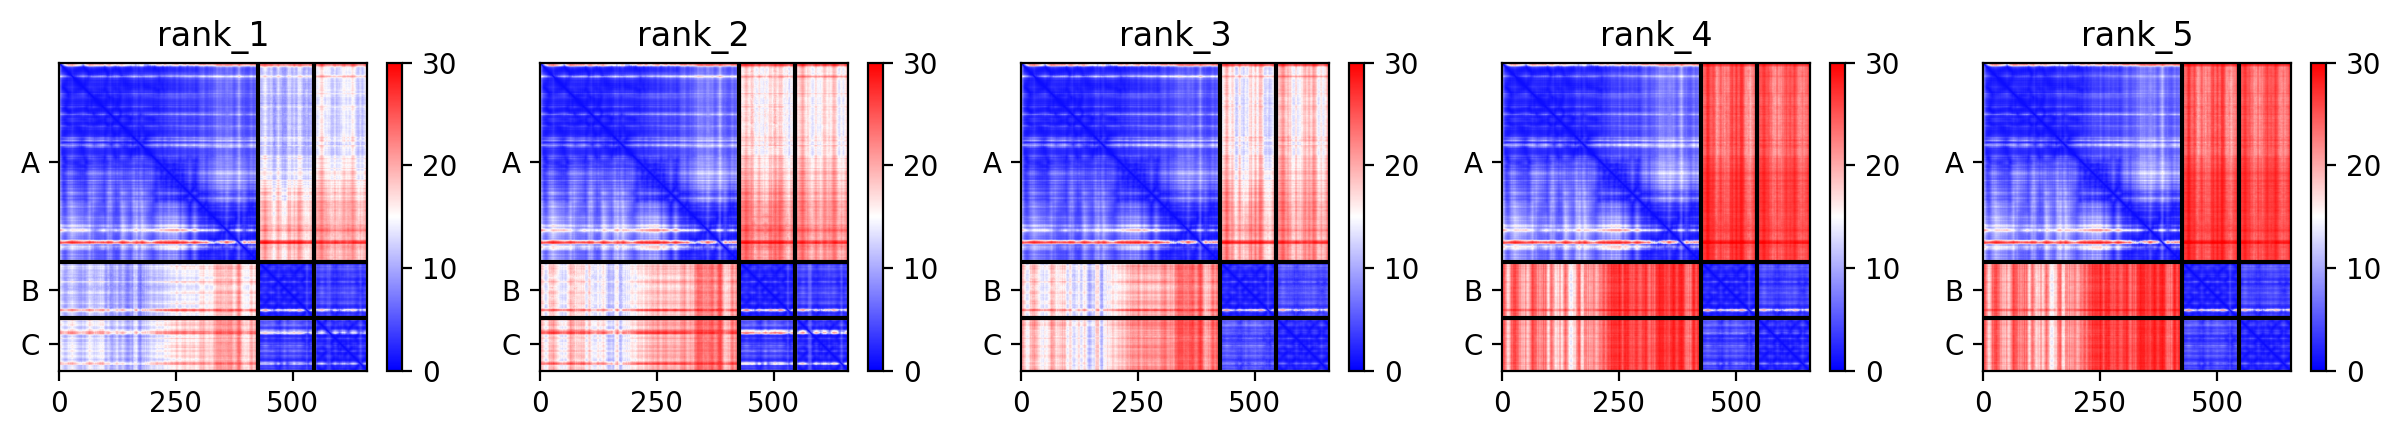
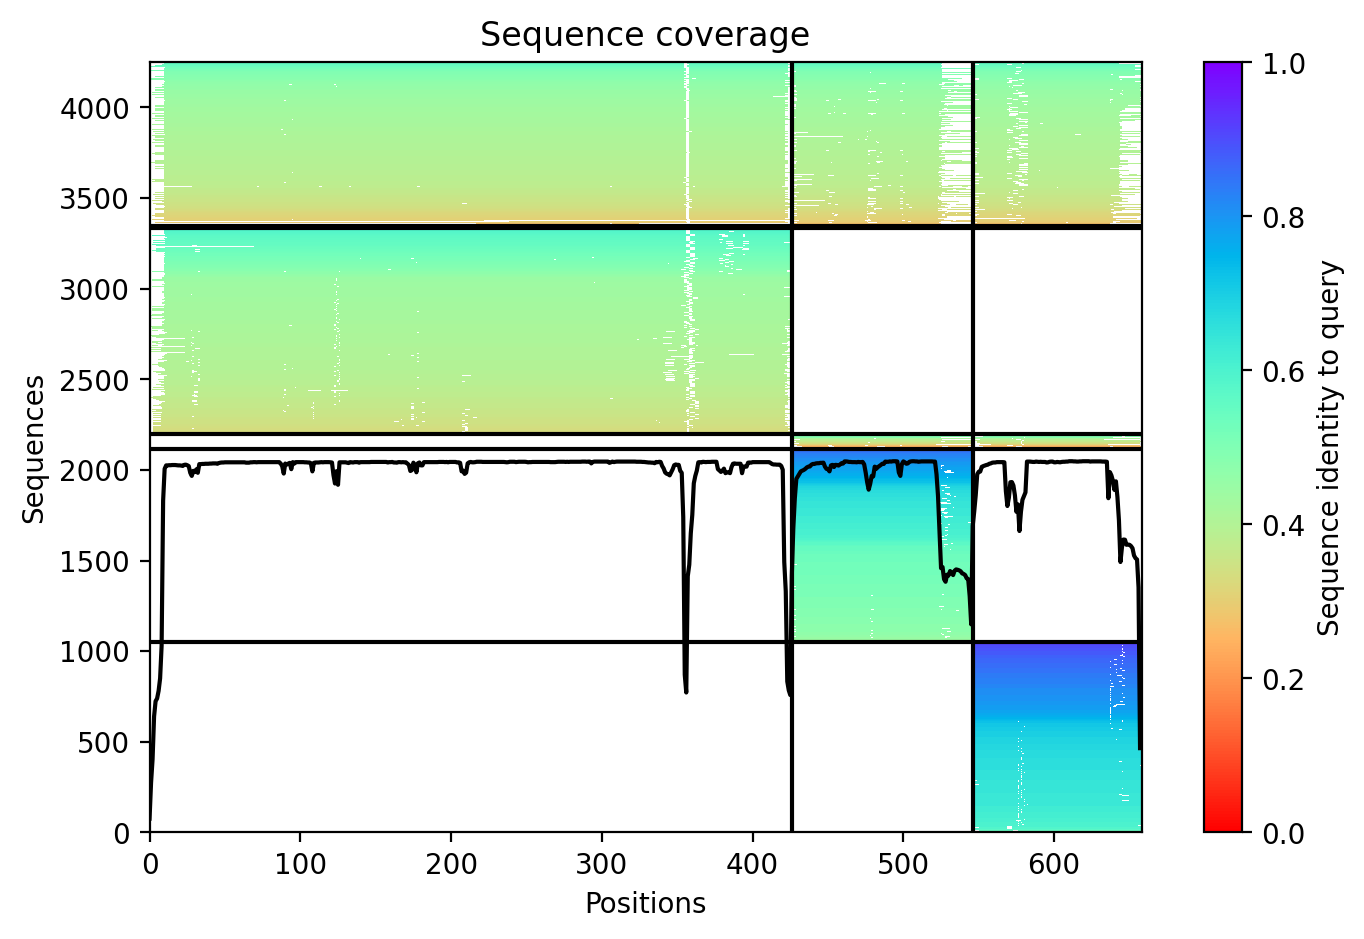
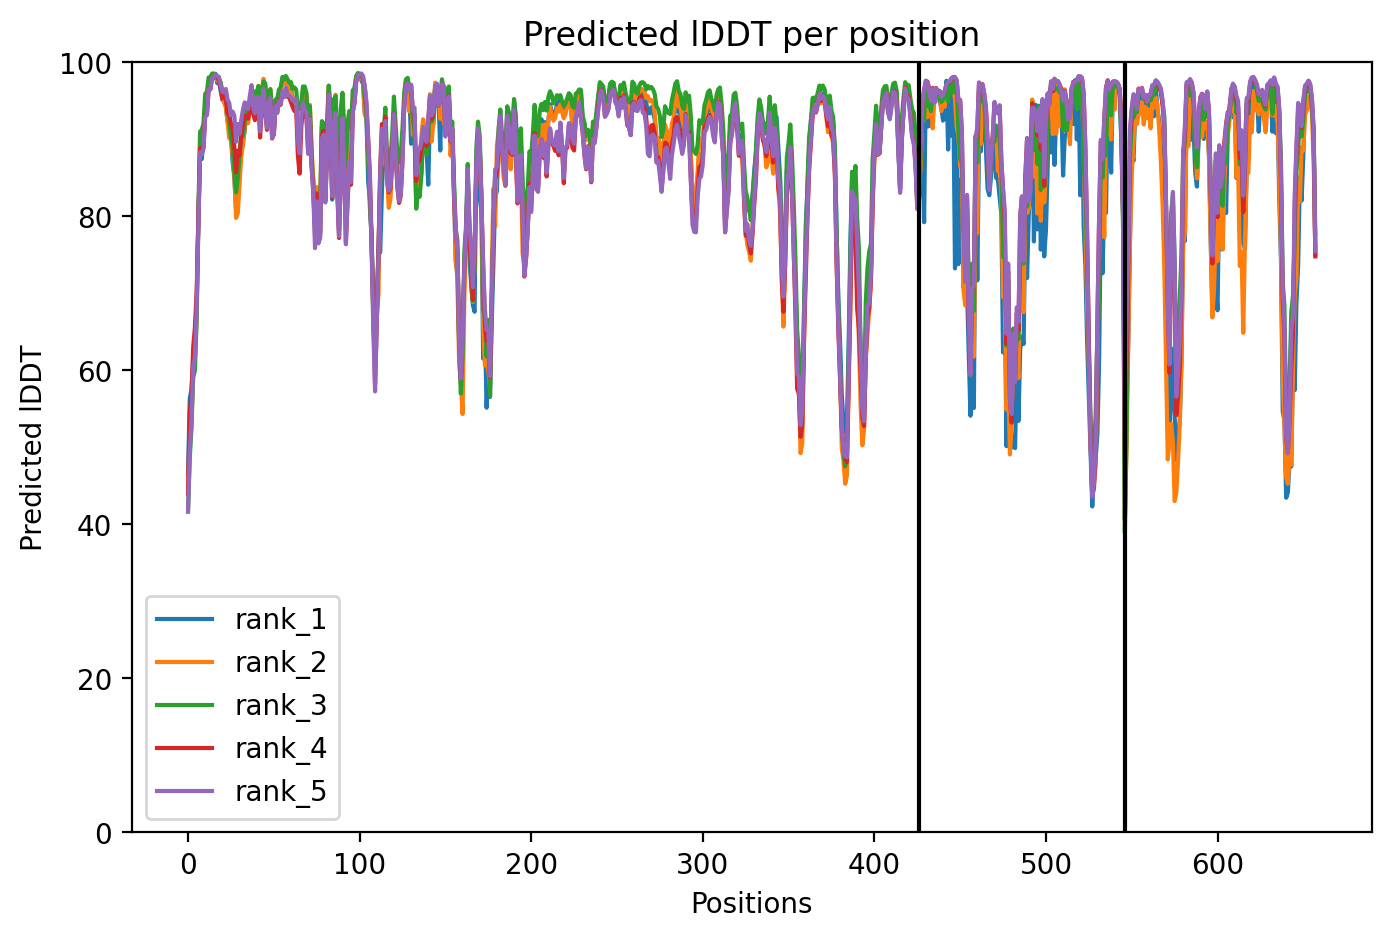

In [8]:
#@title Plots {run: "auto"}
from IPython.display import display, HTML
import base64
from html import escape

# see: https://stackoverflow.com/a/53688522
def image_to_data_url(filename):
  ext = filename.split('.')[-1]
  prefix = f'data:image/{ext};base64,'
  with open(filename, 'rb') as f:
    img = f.read()
  return prefix + base64.b64encode(img).decode('utf-8')

pae = ""
pae_file = os.path.join(jobname,f"{jobname}{jobname_prefix}_pae.png")
if os.path.isfile(pae_file):
    pae = image_to_data_url(pae_file)
cov = image_to_data_url(os.path.join(jobname,f"{jobname}{jobname_prefix}_coverage.png"))
plddt = image_to_data_url(os.path.join(jobname,f"{jobname}{jobname_prefix}_plddt.png"))
display(HTML(f"""
<style>
  img {{
    float:left;
  }}
  .full {{
    max-width:100%;
  }}
  .half {{
    max-width:50%;
  }}
  @media (max-width:640px) {{
    .half {{
      max-width:100%;
    }}
  }}
</style>
<div style="max-width:90%; padding:2em;">
  <h1>Plots for {escape(jobname)}</h1>
  { '<!--' if pae == '' else '' }<img src="{pae}" class="full" />{ '-->' if pae == '' else '' }
  <img src="{cov}" class="half" />
  <img src="{plddt}" class="half" />
</div>
"""))

In [9]:
#@title Package and download results
#@markdown If you are having issues downloading the result archive, try disabling your adblocker and run this cell again. If that fails click on the little folder icon to the left, navigate to file: `jobname.result.zip`, right-click and select \"Download\" (see [screenshot](https://pbs.twimg.com/media/E6wRW2lWUAEOuoe?format=jpg&name=small)).

if msa_mode == "custom":
  print("Don't forget to cite your custom MSA generation method.")

files.download(f"{jobname}.result.zip")

if save_to_google_drive == True and drive:
  uploaded = drive.CreateFile({'title': f"{jobname}.result.zip"})
  uploaded.SetContentFile(f"{jobname}.result.zip")
  uploaded.Upload()
  print(f"Uploaded {jobname}.result.zip to Google Drive with ID {uploaded.get('id')}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Instructions <a name="Instructions"></a>
For detailed instructions, tips and tricks, see recently published paper at [Nature Protocols](https://www.nature.com/articles/s41596-024-01060-5)

**Quick start**
1. Paste your protein sequence(s) in the input field.
2. Press "Runtime" -> "Run all".
3. The pipeline consists of 5 steps. The currently running step is indicated by a circle with a stop sign next to it.

**Result zip file contents**

1. PDB formatted structures sorted by avg. pLDDT and complexes are sorted by pTMscore. (unrelaxed and relaxed if `use_amber` is enabled).
2. Plots of the model quality.
3. Plots of the MSA coverage.
4. Parameter log file.
5. A3M formatted input MSA.
6. A `predicted_aligned_error_v1.json` using [AlphaFold-DB's format](https://alphafold.ebi.ac.uk/faq#faq-7) and a `scores.json` for each model which contains an array (list of lists) for PAE, a list with the average pLDDT and the pTMscore.
7. BibTeX file with citations for all used tools and databases.

At the end of the job a download modal box will pop up with a `jobname.result.zip` file. Additionally, if the `save_to_google_drive` option was selected, the `jobname.result.zip` will be uploaded to your Google Drive.

**MSA generation for complexes**

For the complex prediction we use unpaired and paired MSAs. Unpaired MSA is generated the same way as for the protein structures prediction by searching the UniRef100 and environmental sequences three iterations each.

The paired MSA is generated by searching the UniRef100 database and pairing the best hits sharing the same NCBI taxonomic identifier (=species or sub-species). We only pair sequences if all of the query sequences are present for the respective taxonomic identifier.

**Using a custom MSA as input**

To predict the structure with a custom MSA (A3M formatted): (1) Change the `msa_mode`: to "custom", (2) Wait for an upload box to appear at the end of the "MSA options ..." box. Upload your A3M. The first fasta entry of the A3M must be the query sequence without gaps.

It is also possilbe to provide custom MSAs for complex predictions. Read more about the format [here](https://github.com/sokrypton/ColabFold/issues/76).

As an alternative for MSA generation the [HHblits Toolkit server](https://toolkit.tuebingen.mpg.de/tools/hhblits) can be used. After submitting your query, click "Query Template MSA" -> "Download Full A3M". Download the A3M file and upload it in this notebook.

**PDB100** <a name="pdb100"></a>

As of 23/06/08, we have transitioned from using the PDB70 to a 100% clustered PDB, the PDB100. The construction methodology of PDB100 differs from that of PDB70.

The PDB70 was constructed by running each PDB70 representative sequence through [HHblits](https://github.com/soedinglab/hh-suite) against the [Uniclust30](https://uniclust.mmseqs.com/). On the other hand, the PDB100 is built by searching each PDB100 representative structure with [Foldseek](https://github.com/steineggerlab/foldseek) against the [AlphaFold Database](https://alphafold.ebi.ac.uk).

To maintain compatibility with older Notebook versions and local installations, the generated files and API responses will continue to be named "PDB70", even though we're now using the PDB100.

**Using custom templates** <a name="custom_templates"></a>

To predict the structure with a custom template (PDB or mmCIF formatted): (1) change the `template_mode` to "custom" in the execute cell and (2) wait for an upload box to appear at the end of the "Input Protein" box. Select and upload your templates (multiple choices are possible).

* Templates must follow the four letter PDB naming with lower case letters.

* Templates in mmCIF format must contain `_entity_poly_seq`. An error is thrown if this field is not present. The field `_pdbx_audit_revision_history.revision_date` is automatically generated if it is not present.

* Templates in PDB format are automatically converted to the mmCIF format. `_entity_poly_seq` and `_pdbx_audit_revision_history.revision_date` are automatically generated.

If you encounter problems, please report them to this [issue](https://github.com/sokrypton/ColabFold/issues/177).

**Comparison to the full AlphaFold2 and AlphaFold2 Colab**

This notebook replaces the homology detection and MSA pairing of AlphaFold2 with MMseqs2. For a comparison against the [AlphaFold2 Colab](https://colab.research.google.com/github/deepmind/alphafold/blob/main/notebooks/AlphaFold.ipynb) and the full [AlphaFold2](https://github.com/deepmind/alphafold) system read our [paper](https://www.nature.com/articles/s41592-022-01488-1).

**Troubleshooting**
* Check that the runtime type is set to GPU at "Runtime" -> "Change runtime type".
* Try to restart the session "Runtime" -> "Factory reset runtime".
* Check your input sequence.

**Known issues**
* Google Colab assigns different types of GPUs with varying amount of memory. Some might not have enough memory to predict the structure for a long sequence.
* Your browser can block the pop-up for downloading the result file. You can choose the `save_to_google_drive` option to upload to Google Drive instead or manually download the result file: Click on the little folder icon to the left, navigate to file: `jobname.result.zip`, right-click and select \"Download\" (see [screenshot](https://pbs.twimg.com/media/E6wRW2lWUAEOuoe?format=jpg&name=small)).

**Limitations**
* Computing resources: Our MMseqs2 API can handle ~20-50k requests per day.
* MSAs: MMseqs2 is very precise and sensitive but might find less hits compared to HHblits/HMMer searched against BFD or MGnify.
* We recommend to additionally use the full [AlphaFold2 pipeline](https://github.com/deepmind/alphafold).

**Description of the plots**
*   **Number of sequences per position** - We want to see at least 30 sequences per position, for best performance, ideally 100 sequences.
*   **Predicted lDDT per position** - model confidence (out of 100) at each position. The higher the better.
*   **Predicted Alignment Error** - For homooligomers, this could be a useful metric to assess how confident the model is about the interface. The lower the better.

**Bugs**
- If you encounter any bugs, please report the issue to https://github.com/sokrypton/ColabFold/issues

**License**

The source code of ColabFold is licensed under [MIT](https://raw.githubusercontent.com/sokrypton/ColabFold/main/LICENSE). Additionally, this notebook uses the AlphaFold2 source code and its parameters licensed under [Apache 2.0](https://raw.githubusercontent.com/deepmind/alphafold/main/LICENSE) and [CC BY 4.0](https://creativecommons.org/licenses/by-sa/4.0/) respectively. Read more about the AlphaFold license [here](https://github.com/deepmind/alphafold).

**Acknowledgments**
- We thank the AlphaFold team for developing an excellent model and open sourcing the software.

- [KOBIC](https://kobic.re.kr) and [Söding Lab](https://www.mpinat.mpg.de/soeding) for providing the computational resources for the MMseqs2 MSA server.

- Richard Evans for helping to benchmark the ColabFold's Alphafold-multimer support.

- [David Koes](https://github.com/dkoes) for his awesome [py3Dmol](https://3dmol.csb.pitt.edu/) plugin, without whom these notebooks would be quite boring!

- Do-Yoon Kim for creating the ColabFold logo.

- A colab by Sergey Ovchinnikov ([@sokrypton](https://twitter.com/sokrypton)), Milot Mirdita ([@milot_mirdita](https://twitter.com/milot_mirdita)) and Martin Steinegger ([@thesteinegger](https://twitter.com/thesteinegger)).


In [11]:
# ==============================================================================
# PHYSIOLOGICAL BENCHMARK EVALUATOR: FULL-LENGTH ECARIN (656 AA COMPLEX)
# ==============================================================================
import os, glob, json, urllib.request, csv, zipfile, re
import numpy as np

# 1. Download native 9CLP.cif if missing
if not os.path.exists("9CLP.cif"):
    print("Downloading 9CLP.cif from RCSB...")
    urllib.request.urlretrieve("https://files.rcsb.org/download/9CLP.cif", "9CLP.cif")

# 2. Coordinate Parsers & Kabsch Algorithm
def parse_atoms(fpath):
    atoms, is_cif = [], fpath.endswith(".cif")
    with open(fpath, 'r', encoding='utf-8', errors='ignore') as f:
        in_loop, headers = False, []
        for line in f:
            if is_cif:
                l = line.strip()
                if l == 'loop_': in_loop, headers = False, []; continue
                if l.startswith('_atom_site.'): in_loop = True; headers.append(l); continue
                if in_loop:
                    if l.startswith(('#', '_')) or not l: in_loop = False; continue
                    p = l.split()
                    if len(p) >= len(headers):
                        d = dict(zip(headers, p[:len(headers)]))
                        try:
                            atoms.append({
                                'c': d.get('_atom_site.auth_asym_id', d.get('_atom_site.label_asym_id','')),
                                'n': int(d.get('_atom_site.auth_seq_id', d.get('_atom_site.label_seq_id','0'))),
                                'res': d.get('_atom_site.auth_comp_id', d.get('_atom_site.label_comp_id','')),
                                'a': d.get('_atom_site.auth_atom_id', d.get('_atom_site.label_atom_id','')),
                                'el': d.get('_atom_site.type_symbol',''),
                                'xyz': np.array([float(d['_atom_site.Cartn_x']), float(d['_atom_site.Cartn_y']), float(d['_atom_site.Cartn_z'])]),
                                'bf': 20.0
                            })
                        except: pass
            else:
                if line.startswith(('ATOM', 'HETATM')):
                    try:
                        atoms.append({
                            'c': line[21].strip(), 'n': int(line[22:26].strip()),
                            'res': line[17:20].strip(), 'a': line[12:16].strip(),
                            'el': line[76:78].strip() if len(line)>=78 else line[12:16].strip()[0],
                            'xyz': np.array([float(line[30:38]), float(line[38:46]), float(line[46:54])]),
                            'bf': float(line[60:66]) if len(line)>=66 else 0.0
                        })
                    except: pass
    return atoms

def kabsch(P, Q):
    cP, cQ = np.mean(P, axis=0), np.mean(Q, axis=0)
    H = (P - cP).T @ (Q - cQ)
    U, S, Vt = np.linalg.svd(H)
    d = np.linalg.det(Vt.T @ U.T)
    R = Vt.T @ np.diag([1.0, 1.0, d]) @ U.T
    return R, cQ - (R @ cP)

def rmsd(P, Q): return np.sqrt(np.mean(np.sum((P - Q)**2, axis=-1)))

# 3. Native 9CLP Cryo-EM Ground Truth
cif = parse_atoms("9CLP.cif")
nat_ca_a = {a['n']: a['xyz'] for a in cif if a['c'] == 'A' and a['a'] == 'CA' and 195 <= a['n'] <= 614}
nat_hvy_a = {}
for a in cif:
    if a['c'] == 'A' and 195 <= a['n'] <= 614 and a['el'] != 'H':
        nat_hvy_a.setdefault(a['n'], []).append(a['xyz'])

nat_seq_ca_h = [a['xyz'] for a in cif if a['c'] == 'H' and a['a'] == 'CA']
nat_seq_ca_l = [a['xyz'] for a in cif if a['c'] == 'L' and a['a'] == 'CA']

def group_antibody_heavy(chain_id):
    groups, cur_res, cur_atoms = [], None, []
    for a in cif:
        if a['el'] == 'H' or a['c'] != chain_id: continue
        rid = a['n']
        if rid != cur_res:
            if cur_atoms: groups.append(cur_atoms)
            cur_res, cur_atoms = rid, []
        cur_atoms.append(a['xyz'])
    if cur_atoms: groups.append(cur_atoms)
    return groups

nat_h_hvy_seq = group_antibody_heavy('H')
nat_l_hvy_seq = group_antibody_heavy('L')

contacts, int_rec_res, int_lig_res = [], set(), set()
for rn, r_atoms in nat_hvy_a.items():
    r_arr = np.array(r_atoms)
    for h_idx, h_atoms in enumerate(nat_h_hvy_seq):
        d = np.min(np.linalg.norm(r_arr[:, None, :] - np.array(h_atoms)[None, :, :], axis=-1))
        if d <= 5.0: contacts.append((rn, ('H', h_idx))); int_rec_res.add(rn); int_lig_res.add(('H', h_idx))
        elif d <= 10.0: int_rec_res.add(rn); int_lig_res.add(('H', h_idx))
    for l_idx, l_atoms in enumerate(nat_l_hvy_seq):
        d = np.min(np.linalg.norm(r_arr[:, None, :] - np.array(l_atoms)[None, :, :], axis=-1))
        if d <= 5.0: contacts.append((rn, ('L', l_idx))); int_rec_res.add(rn); int_lig_res.add(('L', l_idx))
        elif d <= 10.0: int_rec_res.add(rn); int_lig_res.add(('L', l_idx))

print(f"Native 9CLP Cryo-EM: {len(contacts)} contacts (<5.0 A), {len(int_rec_res)} interface residues on Ecarin.")

# 4. Locate All AlphaFold Models
for z in glob.glob("**/*.result.zip", recursive=True) + glob.glob("*.zip"):
    try:
        with zipfile.ZipFile(z, 'r') as zr: zr.extractall(".")
    except: pass

pdbs = sorted([f for f in glob.glob("**/*rank*.pdb", recursive=True) if "overlay" not in f and "ref" not in f and not os.path.basename(f).startswith("9CLP.")])
if not pdbs:
    pdbs = sorted([f for f in glob.glob("**/*.pdb", recursive=True) if "overlay" not in f and "ref" not in f and not os.path.basename(f).startswith("9CLP.")])

rank_map = {}
for f in pdbs:
    m = re.search(r'rank_\d{3}', os.path.basename(f))
    rk = m.group(0) if m else f
    if rk not in rank_map: rank_map[rk] = f
models = [rank_map[k] for k in sorted(rank_map.keys())]

if len(models) == 0:
    print("\n" + "="*80)
    print("STATUS: No prediction PDB files found yet!")
    print("Please check the 'Run Prediction' cell above:")
    print("  - If it is currently running (spinning circle), allow it ~15-20 mins to finish.")
    print("  - Once it shows a green checkmark (✓), run this cell again.")
    print("="*80)
else:
    print(f"Found {len(models)} AlphaFold models to evaluate.")

    # 5. Evaluate Models with True Full-Length Offset (+190)
    results = []
    top_entry = None
    for idx, mpath in enumerate(models):
        m_atoms = parse_atoms(mpath)

        m_ca_a, m_hvy_a, m_bf_a = {}, {}, []
        m_ca_h, m_hvy_h_seq, m_bf_h = [], [], []
        cur_h_n, cur_h_at = None, []
        m_ca_l, m_hvy_l_seq, m_bf_l = [], [], []
        cur_l_n, cur_l_at = None, []

        for a in m_atoms:
            if a['el'] == 'H': continue
            c, n, aname, xyz, bf = a['c'], a['n'], a['a'], a['xyz'], a['bf']

            if c == 'A':
                nat_n = n + 190
                if 195 <= nat_n <= 614:
                    if aname == 'CA': m_ca_a[nat_n] = xyz; m_bf_a.append(bf)
                    m_hvy_a.setdefault(nat_n, []).append(xyz)
            elif c == 'B':
                if aname == 'CA': m_ca_h.append(xyz); m_bf_h.append(bf)
                if n != cur_h_n:
                    if cur_h_at: m_hvy_h_seq.append(cur_h_at)
                    cur_h_n, cur_h_at = n, []
                cur_h_at.append(xyz)
            elif c == 'C':
                if aname == 'CA': m_ca_l.append(xyz); m_bf_l.append(bf)
                if n != cur_l_n:
                    if cur_l_at: m_hvy_l_seq.append(cur_l_at)
                    cur_l_n, cur_l_at = n, []
                cur_l_at.append(xyz)
        if cur_h_at: m_hvy_h_seq.append(cur_h_at)
        if cur_l_at: m_hvy_l_seq.append(cur_l_at)

        # Domain CA RMSDs
        mp_common = sorted(set(range(195, 388)) & set(m_ca_a.keys()) & set(nat_ca_a.keys()))
        dis_common = sorted(set(range(388, 486)) & set(m_ca_a.keys()) & set(nat_ca_a.keys()))
        crd_common = sorted(set(range(486, 615)) & set(m_ca_a.keys()) & set(nat_ca_a.keys()))
        full_common = sorted(set(range(195, 615)) & set(m_ca_a.keys()) & set(nat_ca_a.keys()))

        R_mp, t_mp = kabsch(np.array([m_ca_a[k] for k in mp_common]), np.array([nat_ca_a[k] for k in mp_common]))
        rmsd_mp = rmsd((R_mp @ np.array([m_ca_a[k] for k in mp_common]).T).T + t_mp, np.array([nat_ca_a[k] for k in mp_common]))

        R_dis, t_dis = kabsch(np.array([m_ca_a[k] for k in dis_common]), np.array([nat_ca_a[k] for k in dis_common]))
        rmsd_dis = rmsd((R_dis @ np.array([m_ca_a[k] for k in dis_common]).T).T + t_dis, np.array([nat_ca_a[k] for k in dis_common]))

        p_crd = np.array([m_ca_a[k] for k in crd_common])
        q_crd = np.array([nat_ca_a[k] for k in crd_common])
        R_crd, t_crd = kabsch(p_crd, q_crd)
        rmsd_crd = rmsd((R_crd @ p_crd.T).T + t_crd, q_crd)

        R_full, t_full = kabsch(np.array([m_ca_a[k] for k in full_common]), np.array([nat_ca_a[k] for k in full_common]))
        rmsd_full_enzyme = rmsd((R_full @ np.array([m_ca_a[k] for k in full_common]).T).T + t_full, np.array([nat_ca_a[k] for k in full_common]))

        # DockQ / CAPRI Metrics (Receptor: CRD Exosite)
        recov = 0
        for rn, lig_desc in contacts:
            if rn not in m_hvy_a: continue
            ch, idx_seq = lig_desc
            m_lig = m_hvy_h_seq if ch == 'H' else m_hvy_l_seq
            if idx_seq >= len(m_lig): continue
            d = np.min(np.linalg.norm(np.array(m_hvy_a[rn])[:, None, :] - np.array(m_lig[idx_seq])[None, :, :], axis=-1))
            if d <= 5.0: recov += 1
        Fnat = recov / len(contacts) if contacts else 0.0

        int_r_common = sorted(int_rec_res & set(m_ca_a.keys()) & set(nat_ca_a.keys()))
        min_h = min(len(m_ca_h), len(nat_seq_ca_h))
        min_l = min(len(m_ca_l), len(nat_seq_ca_l))
        int_h = [i for i in range(min_h) if ('H', i) in int_lig_res]
        int_l = [i for i in range(min_l) if ('L', i) in int_lig_res]

        p_int = np.vstack([np.array([m_ca_a[k] for k in int_r_common])] +
                          ([np.array([m_ca_h[i] for i in int_h])] if int_h else []) +
                          ([np.array([m_ca_l[i] for i in int_l])] if int_l else []))
        q_int = np.vstack([np.array([nat_ca_a[k] for k in int_r_common])] +
                          ([np.array([nat_seq_ca_h[i] for i in int_h])] if int_h else []) +
                          ([np.array([nat_seq_ca_l[i] for i in int_l])] if int_l else []))
        R_int, t_int = kabsch(p_int, q_int)
        iRMSD = rmsd((R_int @ p_int.T).T + t_int, q_int)

        p_lig = np.vstack([np.array(m_ca_h[:min_h]), np.array(m_ca_l[:min_l])])
        q_lig = np.vstack([np.array(nat_seq_ca_h[:min_h]), np.array(nat_seq_ca_l[:min_l])])
        p_lig_on_rec = (R_crd @ p_lig.T).T + t_crd
        lRMSD = rmsd(p_lig_on_rec, q_lig)

        def f_dockq(rmsd_val, d1): return 1.0 / (1.0 + (rmsd_val / d1)**2)
        DockQ = (Fnat + f_dockq(iRMSD, 1.5) + f_dockq(lRMSD, 8.5)) / 3.0

        if Fnat >= 0.5 and (lRMSD <= 1.0 or iRMSD <= 1.0): capri = "High"
        elif (Fnat >= 0.3 and (lRMSD <= 5.0 or iRMSD <= 2.0)) or (Fnat >= 0.5 and lRMSD > 1.0 and iRMSD > 1.0): capri = "Medium"
        elif (Fnat >= 0.1 and (lRMSD <= 10.0 or iRMSD <= 4.0)) or (Fnat >= 0.3 and lRMSD > 5.0 and iRMSD > 2.0): capri = "Acceptable"
        else: capri = "Incorrect"

        R_vh, t_vh = kabsch(np.array(m_ca_h[:min_h]), np.array(nat_seq_ca_h[:min_h]))
        rmsd_vh = rmsd((R_vh @ np.array(m_ca_h[:min_h]).T).T + t_vh, np.array(nat_seq_ca_h[:min_h]))
        R_vl, t_vl = kabsch(np.array(m_ca_l[:min_l]), np.array(nat_seq_ca_l[:min_l]))
        rmsd_vl = rmsd((R_vl @ np.array(m_ca_l[:min_l]).T).T + t_vl, np.array(nat_seq_ca_l[:min_l]))
        R_fv, t_fv = kabsch(p_lig, q_lig)
        rmsd_fv = rmsd((R_fv @ p_lig.T).T + t_fv, q_lig)

        folder = os.path.dirname(mpath) or "."
        m_tag = re.search(r'model_\d', os.path.basename(mpath))
        tag = m_tag.group(0) if m_tag else ""
        iptm, ptm = None, None
        for jf in glob.glob(f"{folder}/*.json"):
            if tag and tag in jf and "scores" in jf:
                try:
                    with open(jf) as f: d = json.load(f)
                    iptm, ptm = d.get('iptm', iptm), d.get('ptm', ptm)
                except: pass
        if iptm is None:
            try:
                with open(os.path.join(folder, "ranking_debug.json")) as f: d = json.load(f)
                for k, v in d.get('iptm', {}).items():
                    if tag in k: iptm = float(v)
                for k, v in d.get('ptm', {}).items():
                    if tag in k: ptm = float(v)
            except: pass

        res = {
            'rank': f"rank_{idx+1:03d}", 'file': os.path.basename(mpath), 'DockQ': DockQ, 'CAPRI': capri,
            'Fnat': Fnat, 'recov': recov, 'iRMSD': iRMSD, 'lRMSD': lRMSD, 'iptm': iptm, 'ptm': ptm,
            'rmsd_mp': rmsd_mp, 'rmsd_dis': rmsd_dis, 'rmsd_crd': rmsd_crd, 'rmsd_full': rmsd_full_enzyme,
            'rmsd_vh': rmsd_vh, 'rmsd_vl': rmsd_vl, 'rmsd_fv': rmsd_fv,
            'plddt_a': np.mean(m_bf_a) if m_bf_a else 0.0,
            'plddt_h': np.mean(m_bf_h) if m_bf_h else 0.0,
            'plddt_l': np.mean(m_bf_l) if m_bf_l else 0.0,
            'R_crd': R_crd, 't_crd': t_crd, 'm_atoms': m_atoms
        }
        results.append(res)
        if idx == 0: top_entry = res

    print("\n" + "="*80)
    print("       PHYSIOLOGICAL DOMAIN-BY-DOMAIN SANITY CHECK (FULL-LENGTH ECARIN)")
    print("="*80)
    print(f"Top Model: {top_entry['file']}")
    print("-"*80)
    print(f"{'Domain / Component':<30} | {'Residues':<10} | {'True CA RMSD':<14} | {'Mean pLDDT':<10}")
    print("-"*80)
    print(f"{'Metalloproteinase Domain':<30} | {'193 aa':<10} | {top_entry['rmsd_mp']:<5.2f} A        | {top_entry['plddt_a']:<5.1f}")
    print(f"{'Disintegrin-like Domain':<30} | {'98 aa':<10}  | {top_entry['rmsd_dis']:<5.2f} A        | {top_entry['plddt_a']:<5.1f}")
    print(f"{'Cysteine-Rich Domain (CRD)':<30} | {'129 aa':<10} | {top_entry['rmsd_crd']:<5.2f} A        | {top_entry['plddt_a']:<5.1f}")
    print(f"{'Full Ecarin Enzyme (Mature)':<30} | {'420 aa':<10} | {top_entry['rmsd_full']:<5.2f} A        | {top_entry['plddt_a']:<5.1f}")
    print("-"*80)
    print(f"{'H11 Antibody VH Domain':<30} | {'120 aa':<10} | {top_entry['rmsd_vh']:<5.2f} A        | {top_entry['plddt_h']:<5.1f}")
    print(f"{'H11 Antibody VL Domain':<30} | {'110 aa':<10} | {top_entry['rmsd_vl']:<5.2f} A        | {top_entry['plddt_l']:<5.1f}")
    print(f"{'H11 Antibody Fv Dimer (VH+VL)':<30} | {'230 aa':<10} | {top_entry['rmsd_fv']:<5.2f} A        | {(top_entry['plddt_h']+top_entry['plddt_l'])/2:<5.1f}")
    print("="*80)

    print("\n" + "="*80)
    print(f"             ALL {len(results)} MODELS EVALUATED (CAPRI BENCHMARK)")
    print("="*80)
    print(f"{'Rank':<10} | {'DockQ':<8} | {'CAPRI':<12} | {'Fnat':<8} | {'iRMSD':<9} | {'lRMSD':<9} | {'ipTM':<8} | {'pTM':<8}")
    print("-"*80)
    for r in results:
        ip_s = f"{r['iptm']:.3f}" if r['iptm'] is not None else "N/A"
        pt_s = f"{r['ptm']:.3f}" if r['ptm'] is not None else "N/A"
        print(f"{r['rank']:<10} | {r['DockQ']:<8.3f} | {r['CAPRI']:<12} | {r['Fnat']:<8.3f} | {r['iRMSD']:<5.2f} A   | {r['lRMSD']:<5.2f} A   | {ip_s:<8} | {pt_s:<8}")
    print("="*80)

    # Save results to CSV
    with open("results.csv", "w", newline="") as cf:
        writer = csv.DictWriter(cf, fieldnames=['rank', 'file', 'DockQ', 'CAPRI', 'Fnat', 'recov', 'iRMSD', 'lRMSD', 'iptm', 'ptm', 'rmsd_mp', 'rmsd_dis', 'rmsd_crd', 'rmsd_full', 'rmsd_vh', 'rmsd_vl', 'rmsd_fv', 'plddt_a', 'plddt_h', 'plddt_l'])
        writer.writeheader()
        for r in results:
            row = {k: v for k, v in r.items() if k not in ['R_crd', 't_crd', 'm_atoms']}
            writer.writerow(row)
    print("Results exported to results.csv")

Native 9CLP Cryo-EM: 42 contacts (<5.0 A), 37 interface residues on Ecarin.
Found 20 AlphaFold models to evaluate.

       PHYSIOLOGICAL DOMAIN-BY-DOMAIN SANITY CHECK (FULL-LENGTH ECARIN)
Top Model: 9CLP_v2_r20_2a977_unrelaxed_rank_001_alphafold2_multimer_v3_model_5_seed_003.pdb
--------------------------------------------------------------------------------
Domain / Component             | Residues   | True CA RMSD   | Mean pLDDT
--------------------------------------------------------------------------------
Metalloproteinase Domain       | 193 aa     | 1.06  A        | 88.0 
Disintegrin-like Domain        | 98 aa       | 0.97  A        | 88.0 
Cysteine-Rich Domain (CRD)     | 129 aa     | 1.15  A        | 88.0 
Full Ecarin Enzyme (Mature)    | 420 aa     | 1.62  A        | 88.0 
--------------------------------------------------------------------------------
H11 Antibody VH Domain         | 120 aa     | 1.27  A        | 81.1 
H11 Antibody VL Domain         | 110 aa     | 0.77  A    

In [12]:
!pip install -q py3Dmol
import py3Dmol

view = py3Dmol.view(width=750, height=450)
with open("overlay_full_complex_rank001.pdb", "r") as f:
    view.addModel(f.read(), "pdb")

# 1. Native Cryo-EM 9CLP (Green = Ecarin, Blue = H11 Fab)
view.setStyle({'chain': 'A'}, {'cartoon': {'color': '#2ca02c'}})
view.setStyle({'chain': 'H'}, {'cartoon': {'color': '#1f77b4'}})
view.setStyle({'chain': 'L'}, {'cartoon': {'color': '#aec7e8'}})

# 2. Predicted AlphaFold Pose (Light Green = Ecarin, Orange/Red = Predicted H11)
view.setStyle({'chain': 'D'}, {'cartoon': {'color': '#98df8a', 'opacity': 0.6}})
view.setStyle({'chain': 'E'}, {'cartoon': {'color': '#d62728', 'opacity': 0.85}})
view.setStyle({'chain': 'F'}, {'cartoon': {'color': '#ff7f0e', 'opacity': 0.85}})

view.zoomTo()
view.show()

FileNotFoundError: [Errno 2] No such file or directory: 'overlay_full_complex_rank001.pdb'

In [ ]:
!nvidia-smi